In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df0=pd.read_excel('../dataset/CaliforniaData/Telco_customer_churn.xlsx')
df = df0.copy()

In [3]:
df.head(20)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices
5,4190-MFLUW,1,United States,California,Los Angeles,90020,"34.066367, -118.309868",34.066367,-118.309868,Female,...,Month-to-month,No,Credit card (automatic),55.20,528.35,Yes,1,78,5925,Competitor offered higher download speeds
6,8779-QRDMV,1,United States,California,Los Angeles,90022,"34.02381, -118.156582",34.023810,-118.156582,Male,...,Month-to-month,Yes,Electronic check,39.65,39.65,Yes,1,100,5433,Competitor offered more data
7,1066-JKSGK,1,United States,California,Los Angeles,90024,"34.066303, -118.435479",34.066303,-118.435479,Male,...,Month-to-month,No,Mailed check,20.15,20.15,Yes,1,92,4832,Competitor made better offer
8,6467-CHFZW,1,United States,California,Los Angeles,90028,"34.099869, -118.326843",34.099869,-118.326843,Male,...,Month-to-month,Yes,Electronic check,99.35,4749.15,Yes,1,77,5789,Competitor had better devices
9,8665-UTDHZ,1,United States,California,Los Angeles,90029,"34.089953, -118.294824",34.089953,-118.294824,Male,...,Month-to-month,No,Electronic check,30.20,30.2,Yes,1,97,2915,Competitor had better devices


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [5]:
df["Churn Reason"].unique

<bound method Series.unique of 0        Competitor made better offer
1                               Moved
2                               Moved
3                               Moved
4       Competitor had better devices
                    ...              
7038                              NaN
7039                              NaN
7040                              NaN
7041                              NaN
7042                              NaN
Name: Churn Reason, Length: 7043, dtype: object>

In [6]:
df.shape

(7043, 33)

In [7]:
resume = pd.DataFrame({
    "dtype": df.dtypes,
    "n_unique": df.nunique(),
    "n_manquants": df.isna().sum(),
    "exemple": df.iloc[0]
})
resume

,dtype,n_unique,n_manquants,exemple
CustomerID,object,7043,0,3668-QPYBK
Count,int64,1,0,1
Country,object,1,0,United States
State,object,1,0,California
City,object,1129,0,Los Angeles
Zip Code,int64,1652,0,90003
Lat Long,object,1652,0,"33.964131, -118.272783"
Latitude,float64,1652,0,33.964131
Longitude,float64,1651,0,-118.272783
Gender,object,2,0,Male


In [8]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [9]:
df["Churn Reason"].unique()

array(['Competitor made better offer', 'Moved',
       'Competitor had better devices',
       'Competitor offered higher download speeds',
       'Competitor offered more data', 'Price too high',
       'Product dissatisfaction', 'Service dissatisfaction',
       'Lack of self-service on Website', 'Network reliability',
       'Limited range of services',
       'Lack of affordable download/upload speed',
       'Long distance charges', 'Extra data charges', "Don't know",
       'Poor expertise of online support',
       'Poor expertise of phone support', 'Attitude of service provider',
       'Attitude of support person', 'Deceased', nan], dtype=object)

In [10]:
df["City"].unique()

array(['Los Angeles', 'Beverly Hills', 'Huntington Park', ..., 'Standish',
       'Tulelake', 'Olympic Valley'], dtype=object)

In [11]:
df["Gender"].value_counts()

Gender
Male      3555
Female    3488
Name: count, dtype: int64

(array([862., 376., 374., 242., 215., 302., 179., 257., 134., 175., 252.,
        129., 209., 133., 153., 174., 120., 200., 112., 142., 198., 148.,
        202., 145., 127., 222., 152., 263., 195., 651.]),
 array([ 0. ,  2.4,  4.8,  7.2,  9.6, 12. , 14.4, 16.8, 19.2, 21.6, 24. ,
        26.4, 28.8, 31.2, 33.6, 36. , 38.4, 40.8, 43.2, 45.6, 48. , 50.4,
        52.8, 55.2, 57.6, 60. , 62.4, 64.8, 67.2, 69.6, 72. ]),
 <BarContainer object of 30 artists>)

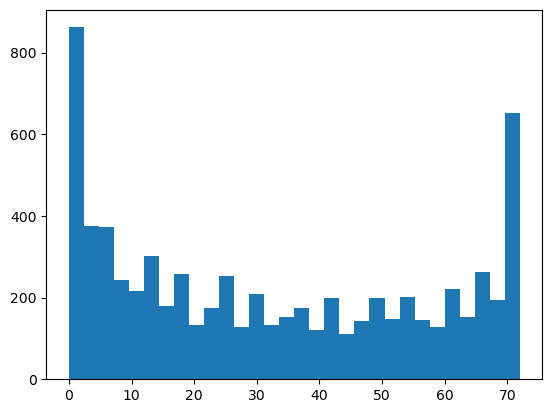

In [12]:
df["Tenure Months"].value_counts()
plt.hist(df["Tenure Months"], bins=30)

In [13]:
df["Churn Label"].describe()


count     7043
unique       2
top         No
freq      5174
Name: Churn Label, dtype: object

In [14]:
pd.crosstab(df["Internet Service"], df["Online Security"], normalize="index").round(2)

Online Security,No,No internet service,Yes
Internet Service,,,
DSL,0.51,0.0,0.49
Fiber optic,0.73,0.0,0.27
No,0.00,1.0,0.00


<Axes: >

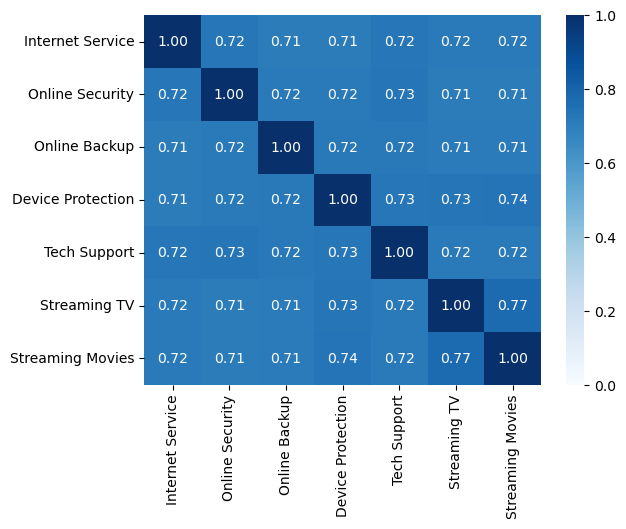

In [15]:
import numpy as np
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

cols = ["Internet Service", "Online Security", "Online Backup", "Device Protection",
        "Tech Support", "Streaming TV", "Streaming Movies"]

V = pd.DataFrame([[cramers_v(df[a], df[b]) for b in cols] for a in cols],
                 index=cols, columns=cols)

import seaborn as sns
sns.heatmap(V, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)

In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = pd.get_dummies(df[cols], drop_first=True).astype(float)
X.insert(0, "const", 1)
pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
          index=X.columns[1:]).sort_values(ascending=False)

c:\Users\ZIAD\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


Internet Service_No                           inf
Online Security_No internet service           inf
Online Backup_No internet service             inf
Streaming Movies_No internet service          inf
Tech Support_No internet service              inf
Device Protection_No internet service         inf
Streaming TV_No internet service              inf
Streaming Movies_Yes                     1.590984
Streaming TV_Yes                         1.584389
Internet Service_Fiber optic             1.471949
Device Protection_Yes                    1.395813
Tech Support_Yes                         1.363223
Online Security_Yes                      1.295062
Online Backup_Yes                        1.273394
dtype: float64

In [17]:
d = df[df["Internet Service"] != "No"]
for c in ["Online Security", "Online Backup", "Device Protection",
          "Tech Support", "Streaming TV", "Streaming Movies"]:
    print(c, round(cramers_v(d["Internet Service"], d[c]), 2))

Online Security 0.22
Online Backup 0.01
Device Protection 0.0
Tech Support 0.21
Streaming TV 0.17
Streaming Movies 0.16


In [18]:
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce"
)
df["Total Charges"].dtype

dtype('float64')

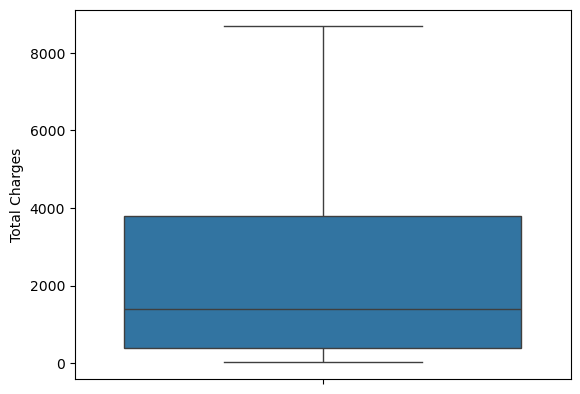

In [19]:
sns.boxplot(df["Total Charges"])
plt.show()

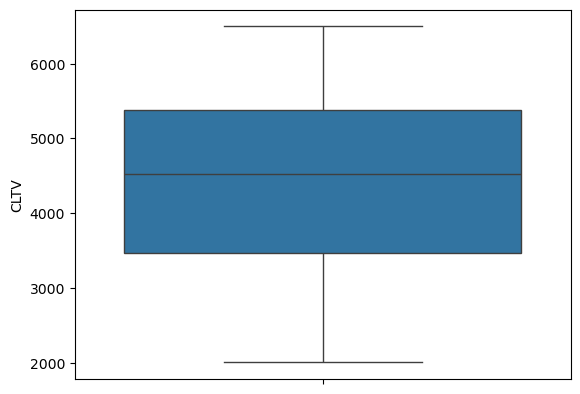

In [20]:
sns.boxplot(df["CLTV"])
plt.show()

In [21]:
df["Total Charges"].corr(df["Monthly Charges"])

np.float64(0.6510648032262025)

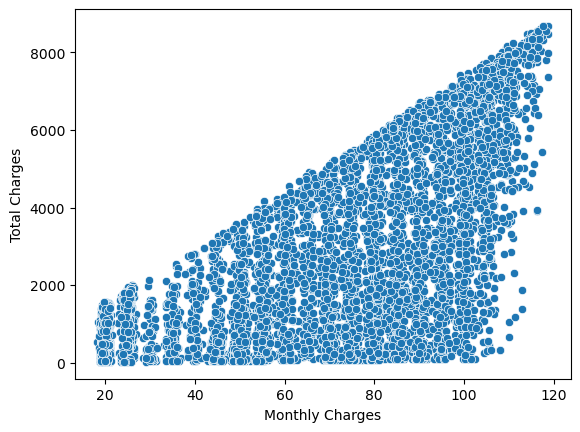

In [22]:
sns.scatterplot(
    data=df,
    x="Monthly Charges",
    y="Total Charges"
)

plt.show()

In [23]:
from scipy.stats import spearmanr

spearmanr(df["Monthly Charges"], df["Total Charges"])

SignificanceResult(statistic=nan, pvalue=nan)

In [24]:
df["Total Charges"].isna().sum()

np.int64(11)

In [25]:
tmp = df[["Total Charges", "Monthly Charges"]].dropna()

spearmanr(
    tmp["Total Charges"],
    tmp["Monthly Charges"]
)

SignificanceResult(statistic=np.float64(0.6380321757758154), pvalue=np.float64(0.0))

In [26]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

produit = df["Tenure Months"] * df["Monthly Charges"]
print(df["Total Charges"].corr(produit))             # attendu : très proche de 1
print(df["Total Charges"].corr(df["Tenure Months"]))  # probablement plus fort que 0.64

0.9995598572867941
0.8258804609332028


In [27]:
df["CLTV"].describe()

count    7043.000000
mean     4400.295755
std      1183.057152
min      2003.000000
25%      3469.000000
50%      4527.000000
75%      5380.500000
max      6500.000000
Name: CLTV, dtype: float64

<Axes: ylabel='CLTV'>

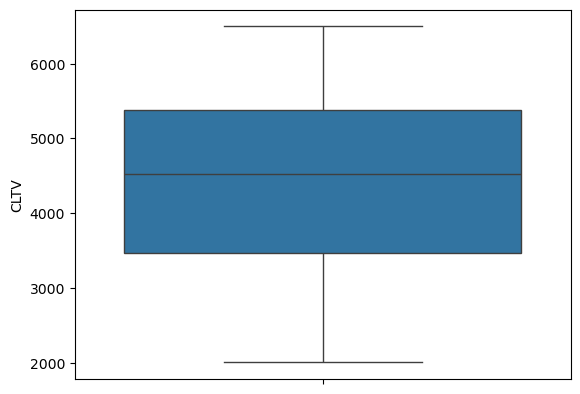

In [28]:
sns.boxplot(df["CLTV"])

## Resultat de l analyse...L'idée des features sans trop approfondir dans l'EDA 
# features inutile
Count ne contient qu une seul val = 1 ..inutile

Country et State de meme..(united states)

Total Charges: est le produit entre monthly charges et tenure months...on perd de lissibilite mais pas d info si on le supprime.. pas de prb pour modele arbre et de meme pour un modele lineaire qui ne sait pas construire la relation prd

Churn Score est une fuite de donnée c est le score qu on cherche

Churn Label est le target mais qualitatif

churn reason est une data leackage aussi .. je ne sait pas si il va quitter ou nn

CLTV(Customer Lifetime Value) de meme aussi ca peut etre une data leackage mais la formule n est pas presente (on est pas sur)

# features utile
City avec 1129 label sans Nan

on peut voir que le zip code et Lat long et Latitude et Longitude sont fortemnt corrélé avec City....donc les eliminer aussi  

Senior Citizen est une feature binaire qui dit si le citoyen depense d une S. citizenship ou non

Tenure Months = ancienneté du client auprès de l'entreprise.

Multiple Lines...nbr de line que possede le client si value=No phone service donc nbr=0 si val=NO nbr=1 sinon nbr=2 (pour ordinal encoding)

Internet Service : si le client a un serve internet ou non et si oui lequel(DSL,Fibre optic)..on pense a faire un one hot encoding entre fibre et dsl et un ordinal encoding entre No et chacun des deux autre ie si No ->(0,0) si Dsl ->(1,0) si Fibre optic ->(0,1)  

Online Security: on s interesse a savoir si le client a la feture ou non donc on pense a fusionner "No" avec "No internet service" et on travaille avec binary encoding

Online Backup: de meme pour cette feature ..binary encoding

Device Protection/Tech Support/Streaming TV/Streaming Movies: de meme aussi....on fait un test de cramer pour voir la dependance avec internet service...on trouve que si on elimine "No internet serivce" pour regarder si la relation est vrai ceux qui ont internet...les resultat donne une relation minimale de 0.01 à 0.21

Contract: contient la durée de contrat de client .. Month-to-month/Two year /One year

Paperless Billing:Yes → le client a accepté la facture dématérialisée.
No → le client reçoit une facture papier.

Payment Method:Electronic check / Mailed check / Bank transfer (automatic) /Credit card (automatic)...ordinal encoding

Churn Value est le target

In [29]:
cols = ["City","Zip Code","Latitude","Longitude","Gender","Senior Citizen","Partner","Dependents","Tenure Months","Phone Service","Multiple Lines","Internet Service","Online Security","Online Backup","Device Protection","Tech Support","Streaming TV","Streaming Movies","Contract","Paperless Billing","Payment Method","Monthly Charges"]

In [30]:
len(cols)

22

# Split stratifié

on fait le split d abord avant de toucher les données pour aucun data leackage

In [31]:
df.isna().sum().sort_values(ascending=False)
# donc pas de prb car on a eliminé churn reason et total charges

Churn Reason         5174
Total Charges          11
CustomerID              0
Count                   0
Country                 0
Zip Code                0
Lat Long                0
State                   0
City                    0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Latitude                0
Longitude               0
Internet Service        0
Multiple Lines          0
Online Security         0
Online Backup           0
Streaming TV            0
Streaming Movies        0
Device Protection       0
Tech Support            0
Paperless Billing       0
Contract                0
Monthly Charges         0
Payment Method          0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
dtype: int64

In [32]:
df.duplicated().sum()
# pas de doublons, donc pas de prb

np.int64(0)

In [33]:
df.nunique().sort_values()
# on a supprimé les colonnes avec une seule valeur unique car il porte aucune info
# de plus on verifié avant par .values_counts() qu' on a pas des modalite très déséquilibrées donc rien a faire


Count                   1
Country                 1
State                   1
Phone Service           2
Dependents              2
Partner                 2
Senior Citizen          2
Gender                  2
Churn Value             2
Paperless Billing       2
Churn Label             2
Multiple Lines          3
Internet Service        3
Online Backup           3
Online Security         3
Tech Support            3
Contract                3
Streaming Movies        3
Streaming TV            3
Device Protection       3
Payment Method          4
Churn Reason           20
Tenure Months          73
Churn Score            85
City                 1129
Monthly Charges      1585
Longitude            1651
Latitude             1652
Lat Long             1652
Zip Code             1652
CLTV                 3438
Total Charges        6530
CustomerID           7043
dtype: int64

In [34]:
from sklearn.model_selection import train_test_split

X = df[cols]; y = df["Churn Value"]
X_tr, X_test, y_tr, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
# pour cross validation
X_train, X_val, y_train, y_val = train_test_split(
    X_tr, y_tr, test_size=0.25, stratify=y_tr, random_state=42,shuffle=True)  # 60/20/20

# on stratifie por garder des labels de target dans les 3 datasets...
# et puisqu'on a pas des timeseries pas de prb pour le shuffle

In [35]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape,X_val.shape, y_val.shape)

(4225, 22) (1409, 22) (4225,) (1409,) (1409, 22) (1409,)


In [36]:
print(y_train.value_counts(), y_val.value_counts() ,y_test.value_counts())

Churn Value
0    3104
1    1121
Name: count, dtype: int64 Churn Value
0    1035
1     374
Name: count, dtype: int64 Churn Value
0    1035
1     374
Name: count, dtype: int64


In [37]:
print(y_train.mean(), y_val.mean(), y_test.mean())
# donc datasets equilibrés, pas de prb pour le train du model

0.26532544378698225 0.2654364797728886 0.2654364797728886


# La cible et le déséquilibre
on observe le desequilibre de la cible aussi

Churn Value
0    3104
1    1121
Name: count, dtype: int64


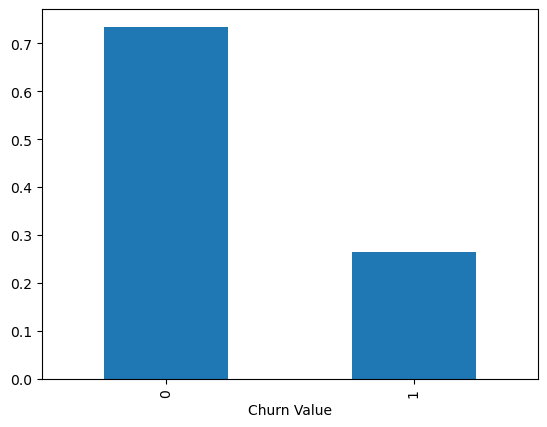

In [38]:
ax = y_train.value_counts(normalize=True).plot.bar()
print(y_train.value_counts())

on remarque un pourcentage de 26,53% des clients churn donc le split stratifié est jusfié ... pas la peine d'ajouté des classe weight ni de focal loss function ni d undersampling

# Qualité de code
on remarque le nombre des val manquants est nul dans df[cols]...donc il reste de verifier si les données sont logics... par exemple si on declare le client sans internet dans "Internet Service" mais on declare differement dans "Online Security"

In [39]:
df.loc[
    (df["Internet Service"] != "No") &
    (df["Online Security"] == "No internet service")
].count()

CustomerID           0
Count                0
Country              0
State                0
City                 0
Zip Code             0
Lat Long             0
Latitude             0
Longitude            0
Gender               0
Senior Citizen       0
Partner              0
Dependents           0
Tenure Months        0
Phone Service        0
Multiple Lines       0
Internet Service     0
Online Security      0
Online Backup        0
Device Protection    0
Tech Support         0
Streaming TV         0
Streaming Movies     0
Contract             0
Paperless Billing    0
Payment Method       0
Monthly Charges      0
Total Charges        0
Churn Label          0
Churn Value          0
Churn Score          0
CLTV                 0
Churn Reason         0
dtype: int64

In [40]:
(
    (df["Internet Service"] != "No") &
    ((df["Online Security"] == "No internet service") | (df["Online Backup"] == "No internet service") | (df["Device Protection"] == "No internet service") | (df["Tech Support"] == "No internet service") | (df["Streaming TV"] == "No internet service") | (df["Streaming Movies"] == "No internet service"))
).sum()
# on voit aucune contradction

np.int64(0)

# EDA - Variables numériques, une par une

In [41]:
num_cols = X_train.select_dtypes('number').columns

In [42]:
num_cols

Index(['Zip Code', 'Latitude', 'Longitude', 'Tenure Months',
       'Monthly Charges'],
      dtype='object')

Zip Code          -0.234115
Monthly Charges   -0.220602
Longitude         -0.056914
Tenure Months      0.248395
Latitude           0.317802
dtype: float64

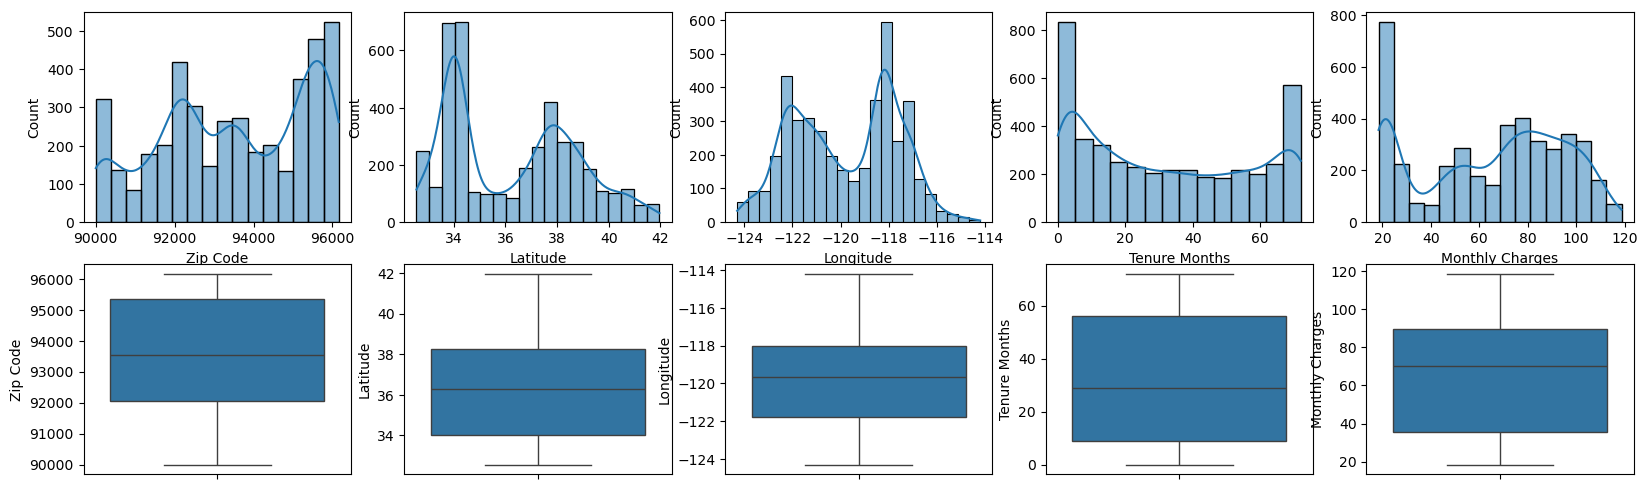

In [43]:
fig, axes = plt.subplots(2, len(num_cols), figsize=(4 * len(num_cols), 6))
for i, c in enumerate(num_cols):
    sns.histplot(X_train[c], kde=True, ax=axes[0, i])
    sns.boxplot(y=X_train[c], ax=axes[1, i])
X_train[num_cols].skew().sort_values()

In [44]:
df["Tenure Months"].describe()
#par regle de Tukey, on considere que les valeurs qui sont en dehors de l'intervalle [Q1-1.5*IQR, Q3+1.5*IQR] sont des outliers. On peut donc calculer ces bornes pour la variable "Tenure Months" et identifier les outliers.

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: Tenure Months, dtype: float64

par analyse des boxplots on ne voit aucune outliers au dehors des moustaches ie intervalle [Q1​−1.5×IQR , Q3+1.5×IQR] par regle de Tukey

on trouve une skewness de :
- Monthly Charges :  -0.220602
- Tenure Months   :   0.248395
donc il s'agit d'une distribtion un peu symétrique (asymétrie faible car inclu dans [-0.5,0.5]).

La clientèle est composée à la fois de nouveaux clients et de clients fidèles, sans qu'un groupe domine excessivement la distribution.
Les montants mensuels facturés sont relativement équilibrés et ne présentent pas de concentration excessive de valeurs élevées ou faibles.

Donc aucune transformation visant à corriger une asymétrie importante (logarithmique ou Box-Cox). Une standarisation seul ca marche

on regardent les histplot des latutude et de longitude on remarque une concentration des clients autour de deux zones:
- Longitude:-118 et -122
- Latitude : 34 et 38
- zipe code : 92000 et 96000


# Variables catégorielles, une par une

In [45]:
cat_cols = X_train.select_dtypes(['object', 'category']).columns

In [46]:
len(cat_cols)

17

Gender                  2
Senior Citizen          2
Partner                 2
Dependents              2
Phone Service           2
Paperless Billing       2
Internet Service        3
Multiple Lines          3
Tech Support            3
Online Security         3
Device Protection       3
Online Backup           3
Streaming Movies        3
Streaming TV            3
Contract                3
Payment Method          4
City                 1107
dtype: int64


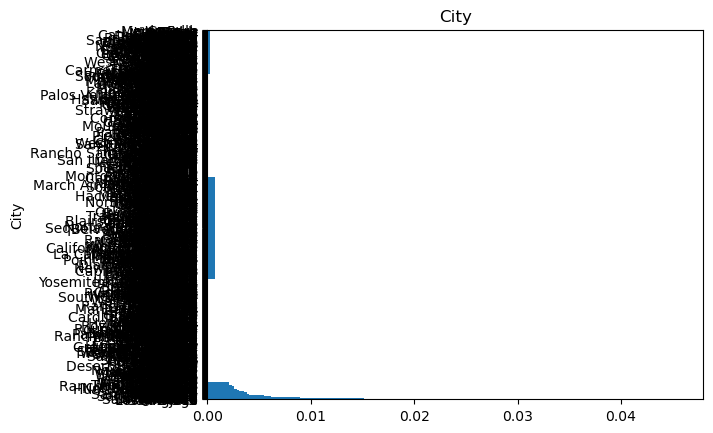

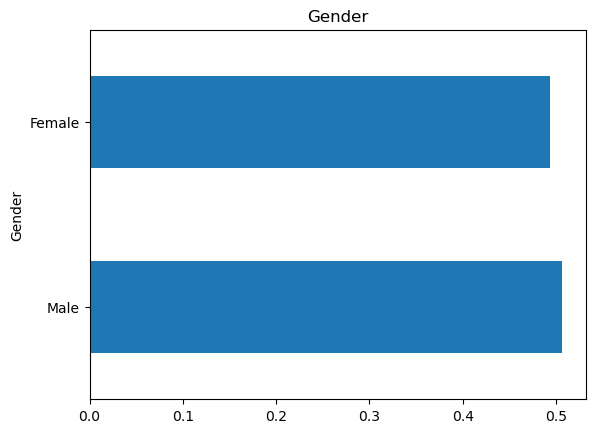

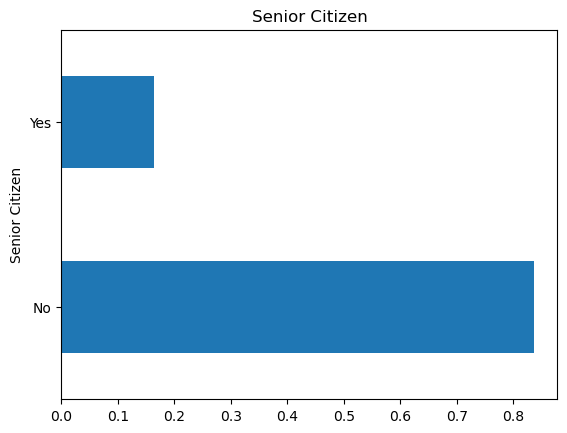

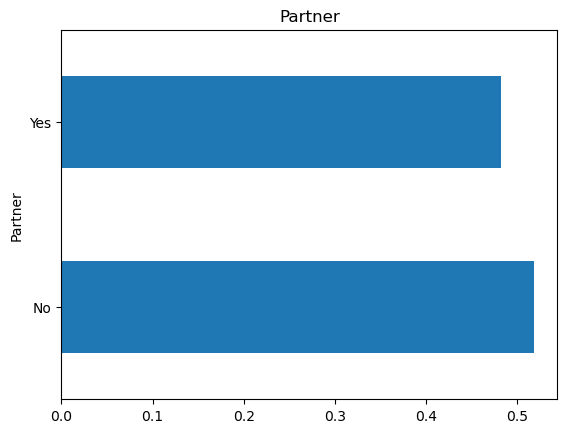

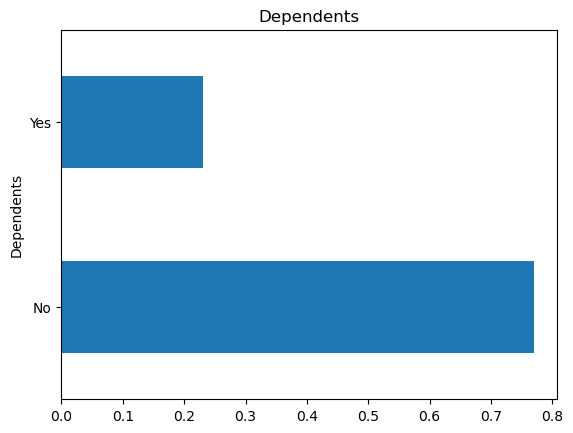

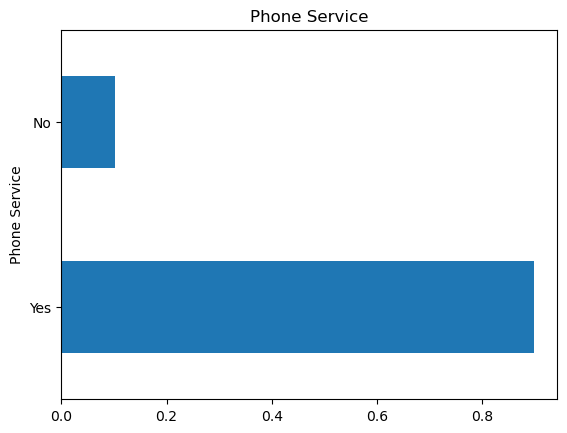

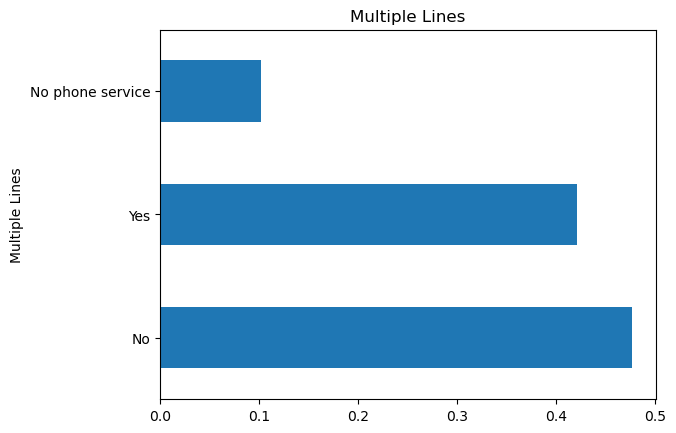

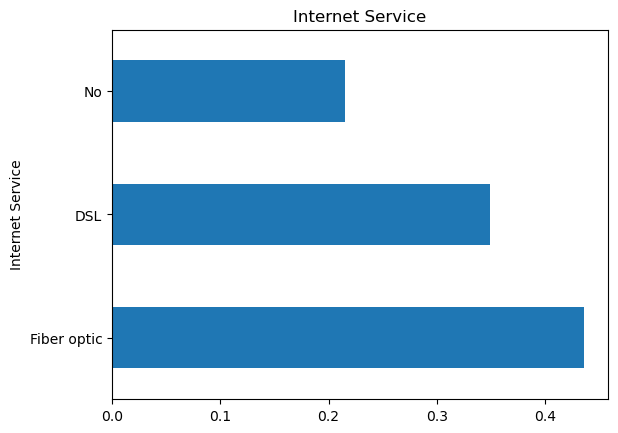

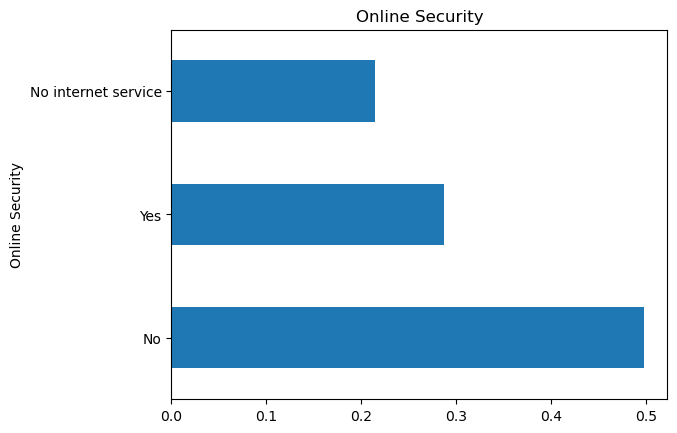

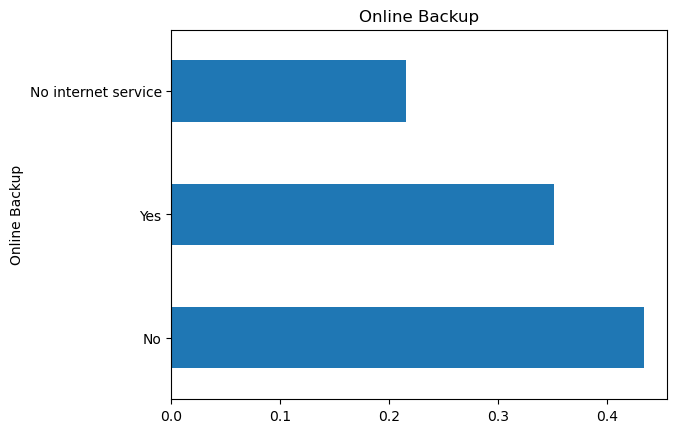

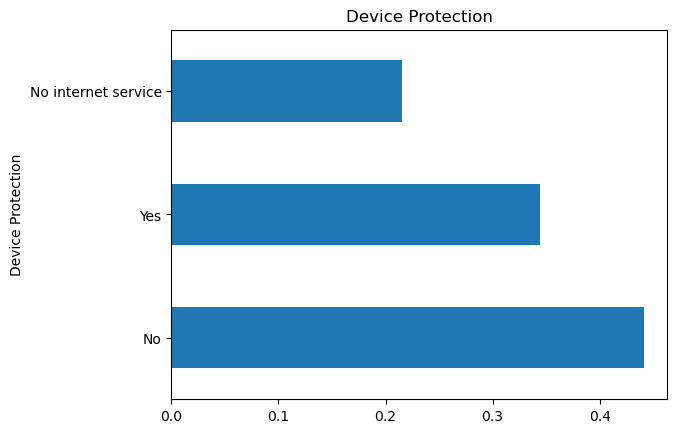

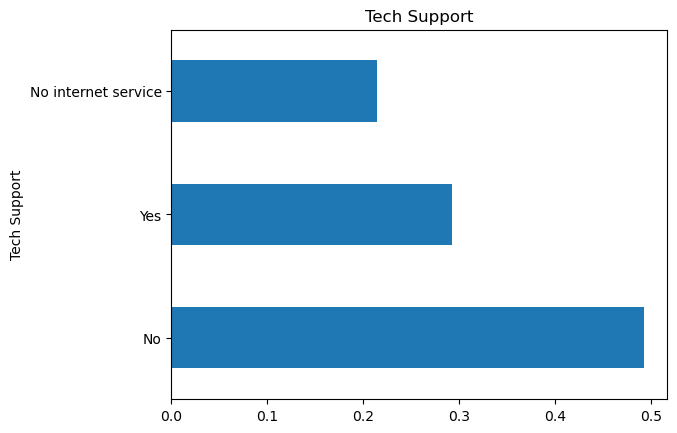

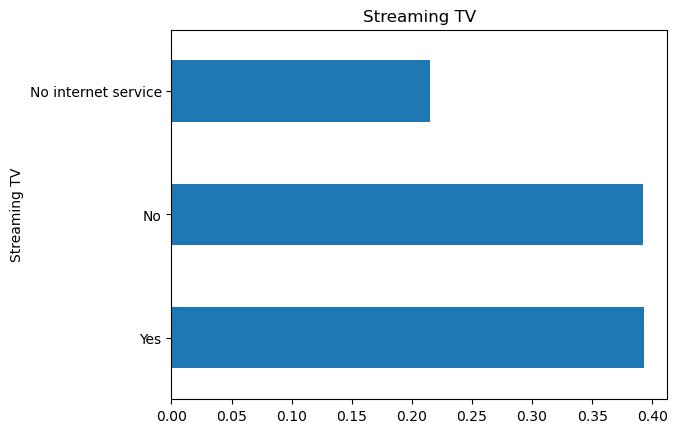

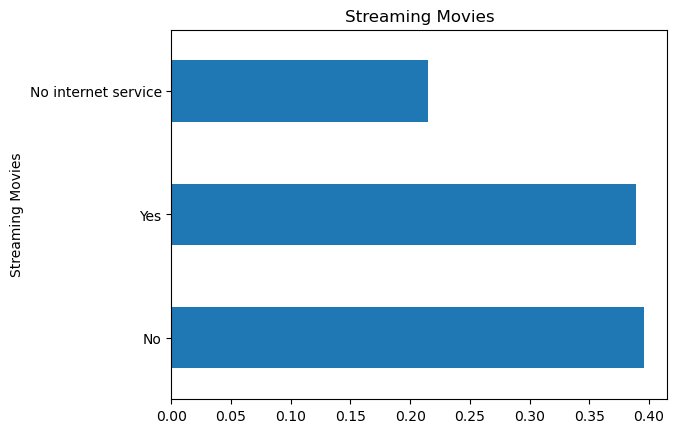

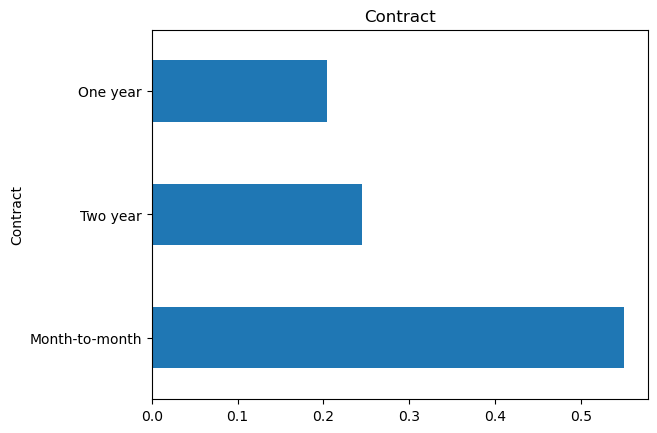

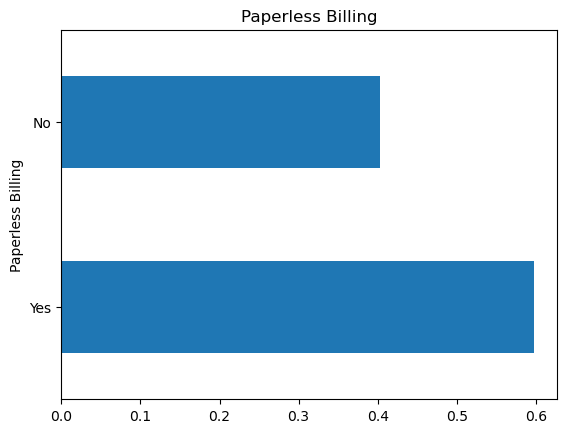

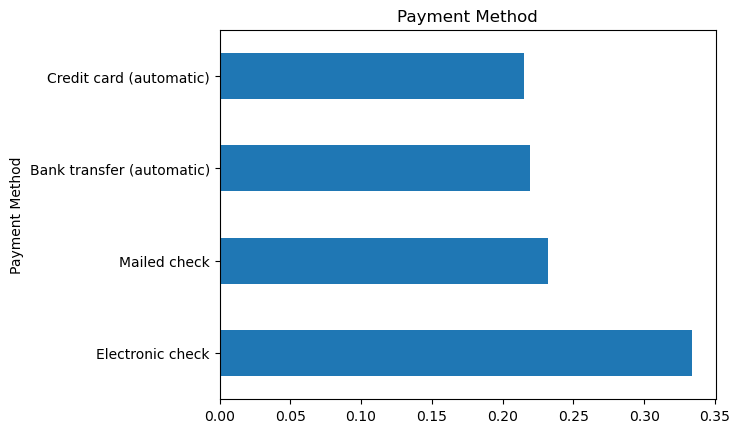

In [47]:
cat_cols = X_train.select_dtypes(['object', 'category']).columns
print(X_train[cat_cols].nunique().sort_values())
for c in cat_cols:
    X_train[c].value_counts(normalize=True).plot.barh(title=c); plt.show()

liste des decisions:
- Gender: 2 modalite bien equilibré (binary encoding)
- Senior Citizen: de meme
- Partner: de meme
- Dependents: de meme
- Phone service:2 mod.. Or on voit un deséquilibre entre les mod(9.6% pour "No")..mais si on observe le signal de target pour les client avec mod "No" on remarque qu'ongarde le meme % que pour le df total..et meme avec 9.6% ca presente 680 client avec assez d'info...donc un simple binary encoding marche
- Multiple Lines: 3 modalité .. on pense a utiliser un ordinal encoding avec "No phone service"=0 et "No"=1 (ie une seul ligne) et "Yes"=2... on choisit ordinal encoding car on remarque un ordre entre les 3 mod
- Internet Service: 3 mod..Plutôt qu'un One-Hot Encoding complet à 3 colonnes (qui introduirait une redondance linéaire parfaite), nous appliquons un Dummy Encoding en fixant la modalité "No" comme état de référence (0, 0). Les deux colonnes binaires résultantes (is_DSL et is_Fiber_optic) encodent ainsi directement la présence et le type d'accès Internet:
    - "DSL"->(1,0)
    - "Fibe optic"->(0,1)
    - "No" -> (0,0) 
- Online Security:3 modalité .. mais on n'intersse pas à voir la mod "No internet service" on peut le voir dans "internet Service".. donc on pense à fusionner "No" et "No internet service" puis utliser un ordinal encoding avec 2 mod(binary encoding)
- City:avec 1129 modalité si on pense à utiliser one hot encoding tout simple on tombera dans une grande dim (pas efficace),et si on utilise frequency encoding meme si on aura une 1 seul dim on remarque une grande diff de frequence entre les mod.. en fait 971 modalité ont une fréquene inf à 0.1%. Donc on pense à les regrouper dans une nouvelle mod "Autre", mais on tombe dans une nouveau problème étant que la mod "Autre" aura une fréquence de 57.59% (dominate) donc on risque à perdre de l'information. La solution trouvé est de regrouper les villes pour quantifier l inforamtion de distance et position (comme des clusters). Or puisqu'on a deja la "Latitude" et la "Longitude" on aura la meme information. Donc on peut éliminer "City"

In [48]:
internet_option_cols = [
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies"
]

# Remplacement propre sur une copie pour l'EDA
df[internet_option_cols] = df[internet_option_cols].replace("No internet service", "No")

# Vérification rapide des modalités restantes
for col in internet_option_cols:
    print(col, "->", df[col].unique())

Online Security -> ['Yes' 'No']
Online Backup -> ['Yes' 'No']
Device Protection -> ['No' 'Yes']
Tech Support -> ['No' 'Yes']
Streaming TV -> ['No' 'Yes']
Streaming Movies -> ['No' 'Yes']


In [49]:
df[df["Phone Service"]=="No"]["Churn Label"].value_counts(normalize=True)

Churn Label
No     0.750733
Yes    0.249267
Name: proportion, dtype: float64

In [50]:
df["Phone Service"].value_counts(normalize=True)

Phone Service
Yes    0.903166
No     0.096834
Name: proportion, dtype: float64

In [51]:
df["City"].nunique()

1129

In [52]:
freqs = df["City"].value_counts(normalize=True)
pct_autre = df["City"].map(freqs).le(0.001).mean()
print(f"Part de 'Autre' (seuil 0.1%) : {pct_autre:.2%}")

Part de 'Autre' (seuil 0.1%) : 57.59%


In [53]:
(freqs<=0.001).sum()

np.int64(971)

C:\Users\ZIAD\AppData\Local\Temp\ipykernel_18968\4203666765.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


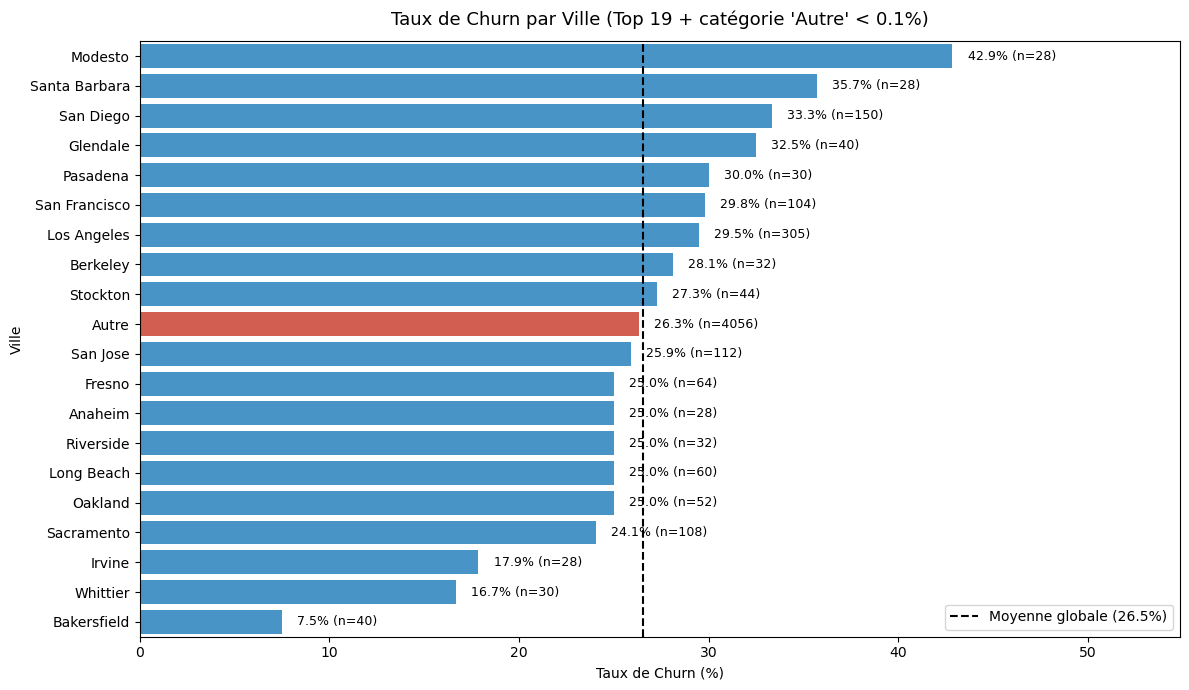

In [54]:
# 1. Créer la colonne regroupée (seuil 0.1 %)
freqs = df["City"].value_counts(normalize=True)
villes_frequentes = freqs[freqs >= 0.001].index

df_viz = df.copy()
df_viz["City_grouped"] = df_viz["City"].where(df_viz["City"].isin(villes_frequentes), "Autre")

# 2. Calculer le taux de churn (en supposant "Yes"/"No" -> 1/0) et l'effectif par modalité
df_viz["Churn_num"] = (df_viz["Churn Label"] == "Yes").astype(int)

stats = (
    df_viz.groupby("City_grouped")
    .agg(
        taux_churn=("Churn_num", "mean"),
        effectif=("Churn_num", "count")
    )
    .sort_values(by="effectif", ascending=False)
)

# 3. Sélectionner les 20 premières modalités (inclut "Autre" + les 19 plus grandes villes)
top_stats = stats.head(20).sort_values(by="taux_churn", ascending=False)
churn_global = df_viz["Churn_num"].mean()

# 4. Affichage du graphique
plt.figure(figsize=(12, 7))
colors = ["#e74c3c" if city == "Autre" else "#3498db" for city in top_stats.index]

ax = sns.barplot(
    x=top_stats["taux_churn"] * 100,
    y=top_stats.index,
    palette=colors
)

# Ligne verticale du taux de churn moyen global
plt.axvline(churn_global * 100, color="black", linestyle="--", linewidth=1.5, label=f"Moyenne globale ({churn_global:.1%})")

# Ajouter les étiquettes (taux % + effectif n) au bout de chaque barre
for i, (taux, n) in enumerate(zip(top_stats["taux_churn"], top_stats["effectif"])):
    ax.text(taux * 100 + 0.8, i, f"{taux:.1%} (n={n})", va="center", fontsize=9)

plt.title("Taux de Churn par Ville (Top 19 + catégorie 'Autre' < 0.1%)", fontsize=13, pad=12)
plt.xlabel("Taux de Churn (%)")
plt.ylabel("Ville")
plt.xlim(0, max(top_stats["taux_churn"] * 100) + 12)
plt.legend()
plt.tight_layout()
plt.show()

In [55]:
# 1) Dépendance fonctionnelle Zip -> City
print(X_train.groupby('Zip Code')['City'].nunique().max())       # 1 => Zip détermine City
print(X_train.groupby('City')['Zip Code'].nunique().describe())  # >1 => l'inverse est faux

# 2) Coordonnées par code postal
print(X_train.groupby('Zip Code')[['Latitude', 'Longitude']].nunique().max())  # 1 => constantes par zip

# 3) Latitude vs Longitude
print(X_train[['Latitude', 'Longitude']].corr(method='pearson'))  # corr=0.999 => quasi linéaire

# 4) Nombre de valeurs distinctes
print(X_train[['City', 'Zip Code']].nunique())

1
count    1107.000000
mean        1.461608
std         2.637728
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        61.000000
Name: Zip Code, dtype: float64
Latitude     1
Longitude    1
dtype: int64
           Latitude  Longitude
Latitude    1.00000   -0.87571
Longitude  -0.87571    1.00000
City        1107
Zip Code    1618
dtype: int64


# Chaque feature contre la cible

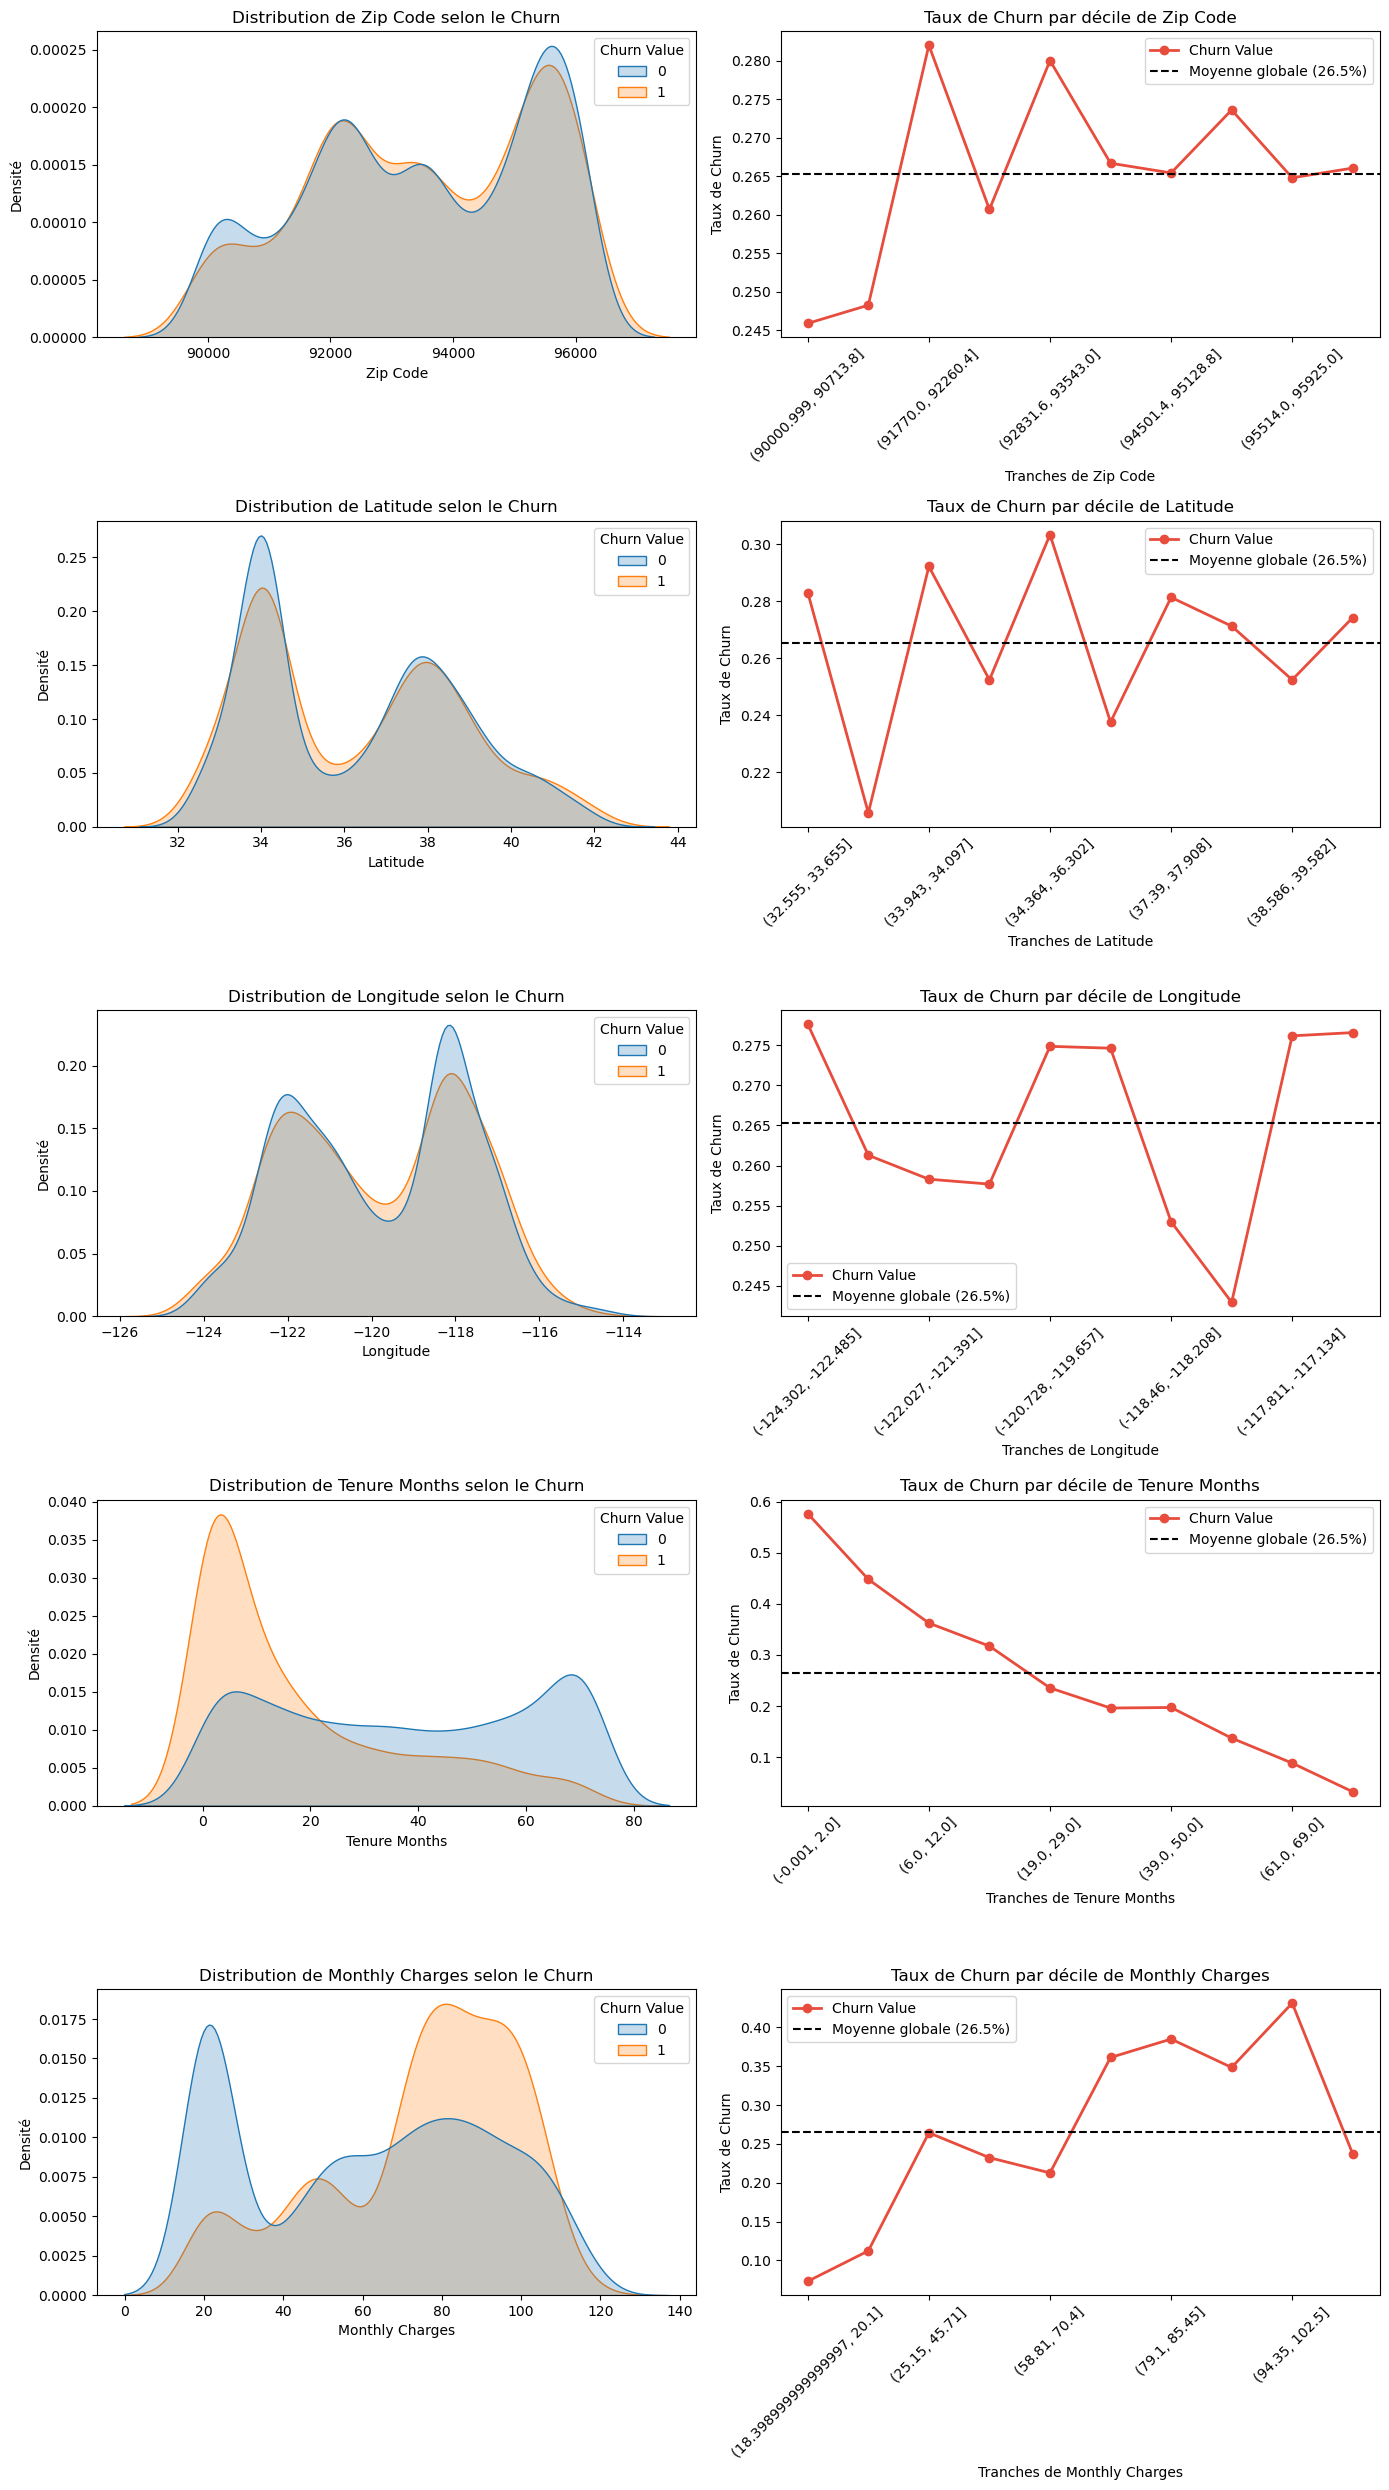

In [56]:

# S'assurer que y_train est numérique (0/1)
y_num = (y_train == "Yes").astype(int) if y_train.dtype == "object" else y_train

n_cols = len(num_cols)
fig, axes = plt.subplots(n_cols, 2, figsize=(14, 5 * n_cols))

# Sécurité : si cols ne contient qu'une seule variable, axes est 1D -> on le force en 2D
if n_cols == 1:
    axes = axes.reshape(1, 2)

for i, col in enumerate(num_cols):
    # --- Graphique de gauche : KDE par classe ---
    sns.kdeplot(
        data=X_train,
        x=col,
        hue=y_train,
        common_norm=False,
        fill=True,
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"Distribution de {col} selon le Churn")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Densité")

    # --- Graphique de droite : Taux de churn par décile ---
    bins = pd.qcut(X_train[col], q=10, duplicates="drop")
    churn_par_bin = y_num.groupby(bins, observed=True).mean()

    churn_par_bin.plot(marker="o", ax=axes[i, 1], color="#e74c3c", linewidth=2)
    axes[i, 1].axhline(
        y_num.mean(),
        ls="--",
        color="black",
        label=f"Moyenne globale ({y_num.mean():.1%})"
    )
    axes[i, 1].set_title(f"Taux de Churn par décile de {col}")
    axes[i, 1].set_xlabel(f"Tranches de {col}")
    axes[i, 1].set_ylabel("Taux de Churn")
    axes[i, 1].tick_params(axis="x", rotation=45)
    axes[i, 1].legend()

plt.tight_layout()
plt.show()

Tenure Months (Ancienneté) : C'est la variable la plus discriminante du jeu de données, avec une relation fortement décroissante et quasi linéaire : le taux de résiliation culmine à environ 58 % durant les deux premiers mois d'abonnement (pic orange massif sur le KDE) avant de chuter régulièrement sous les 5 % pour les clients fidèles de plus de 60 mois. Un simple centrage-réduction (StandardScaler) suffit donc pour l'exploiter directement dans n'importe quel modèle.   

Monthly Charges (Facture mensuelle) : Cette variable présente un fort pouvoir prédictif mais une relation nettement non linéaire. Les petits forfaits autour de 20 $ affichent un taux de churn très bas (~8 %), puis le risque grimpe fortement pour les factures élevées (70 $ à 102 $, atteignant 43 % de churn), avant de chuter brusquement à ~23 % sur le dernier décile (> 102 $). Cette non-monotonie rend l'utilisation d'arbres de décision ou d'une discrétisation en tranches (KBinsDiscretizer) particulièrement pertinente pour les modèles linéaires.   

Zip Code, Latitude et Longitude (Variables géographiques) : Les courbes de densité des clients fidèles et des churners se superposent quasi intégralement (reflétant simplement la densité démographique autour de Los Angeles et San Francisco), et les variations par déciles oscillent faiblement autour de la moyenne globale de 26,5 % (entre 21 % et 30 % maximum). Prises comme variables numériques brutes, elles apportent un signal marginal très faible (et Zip Code ne doit pas être traité comme une grandeur continue), ce qui justifie de tester leur retrait lors de la sélection de variables si elles n'améliorent pas la validation croisée. 

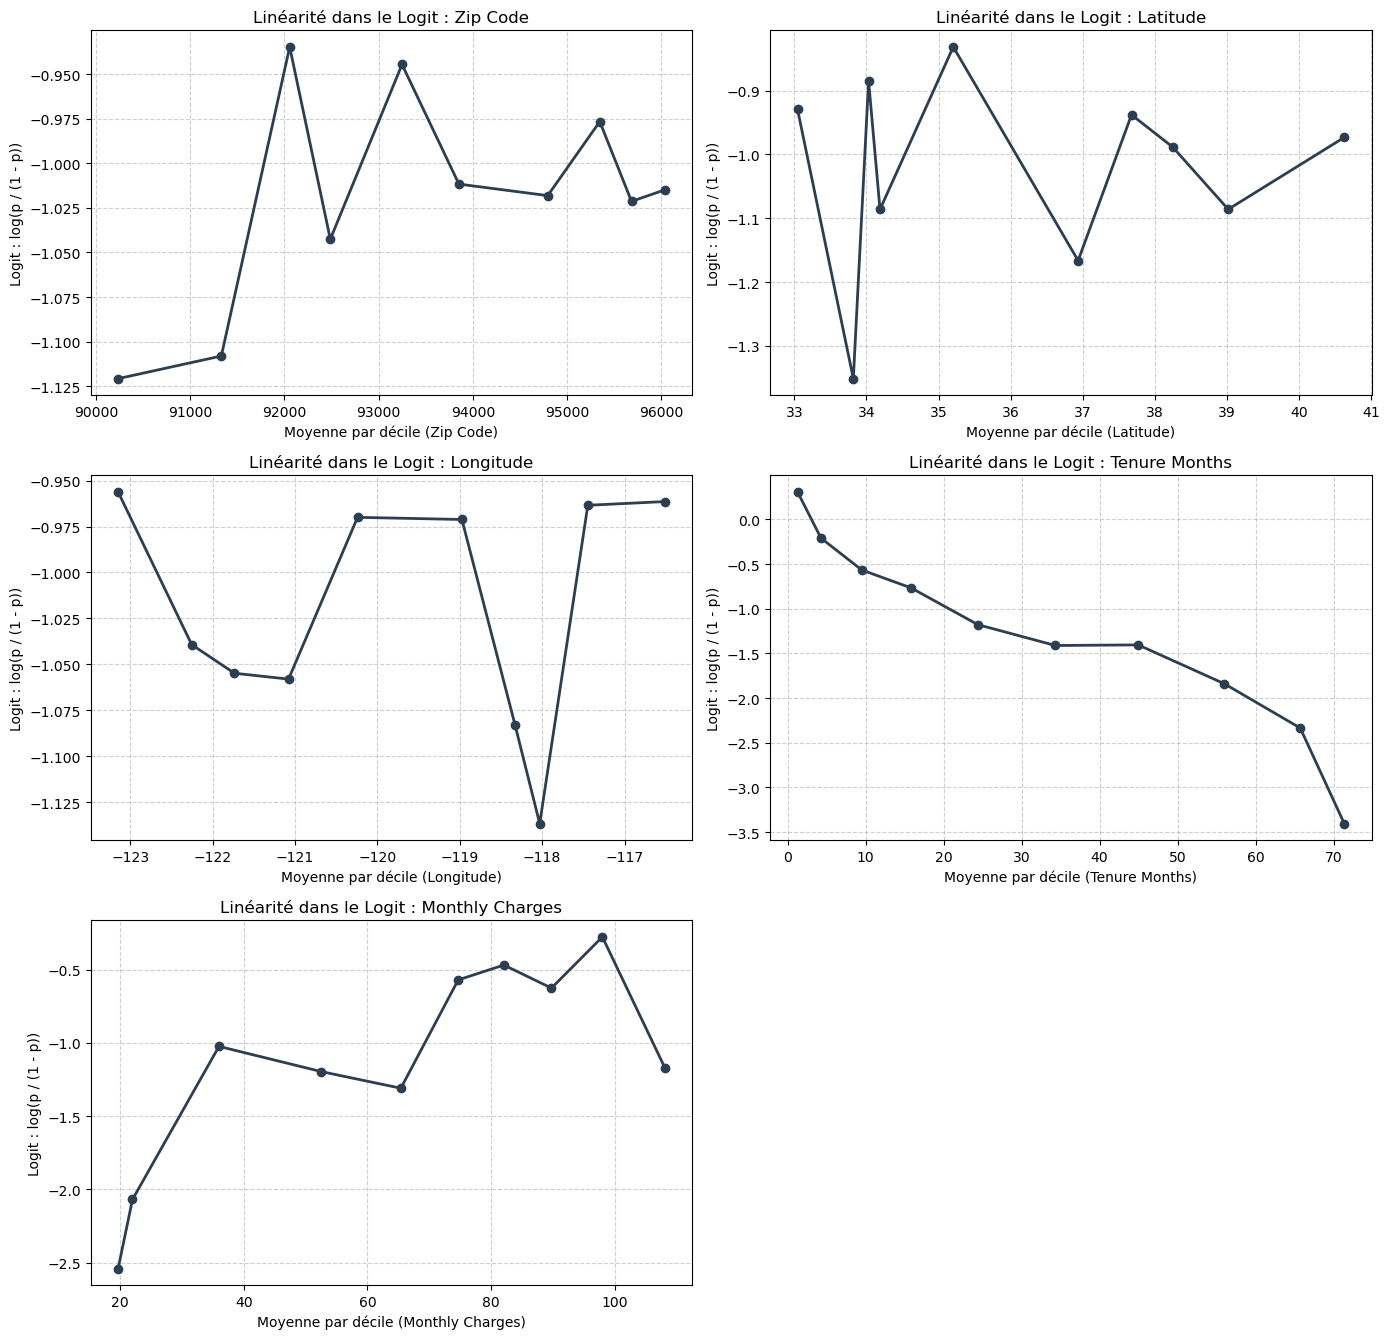

In [57]:
# 1. S'assurer que y_train est numérique (0/1)
y_num = (y_train == "Yes").astype(int) if y_train.dtype == "object" else y_train

# 2. Configuration de la grille (2 graphiques par ligne)
n_vars = len(num_cols)
n_rows = (n_vars + 1) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(14, 4.5 * n_rows))
axes = np.array(axes).flatten()  # Aplatit la grille pour boucler facilement même si n_vars == 1

for i, col in enumerate(num_cols):
    # Découpage en déciles
    bins = pd.qcut(X_train[col], q=10, duplicates="drop")
    
    # Agrégation des statistiques par tranche
    g = (
        pd.DataFrame({"x": X_train[col], "y": y_num})
        .groupby(bins, observed=True)
        .agg(
            rate=("y", "mean"),
            n=("y", "size"),
            x=("x", "mean")
        )
    )
    
    # Calcul du logit avec protection contre log(0)
    p = g["rate"].clip(1e-6, 1 - 1e-6)
    g["logit"] = np.log(p / (1 - p))
    
    # Tracé sur le sous-graphique correspondant
    ax = axes[i]
    ax.plot(g["x"], g["logit"], marker="o", color="#2c3e50", linewidth=2)
    ax.set_title(f"Linéarité dans le Logit : {col}")
    ax.set_xlabel(f"Moyenne par décile ({col})")
    ax.set_ylabel("Logit : log(p / (1 - p))")
    ax.grid(True, linestyle="--", alpha=0.6)

# Masquer les éventuels sous-graphiques vides (si len(num_col) est impair)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

| `Tenure Months` | Décroissance de +0,3 (~58 %) à -3,4 (~3 %), proche d'une droite mais avec une courbure réelle (plateau entre 30 et 45 mois). Dernier décile incertain (±0,45). | Garder. `StandardScaler`, puis tester `SplineTransformer` en validation croisée. Arbres : valeur brute. |

| `Monthly Charges` | Non monotone : bas vers 20 , plateau entre 36 et 65 $, pic vers 98 (~43 %), puis chute au dernier décile (~24 %). | Garder. Tranches (`KBinsDiscretizer`) ou splines pour les modèles linéaires, valeur brute pour les arbres. À vérifier : effet du type d'internet. |

| `Latitude` | Zigzag sans tendance, un décile bas isolé près de 33,8. | Exclue des modèles linéaires. Testée en paire avec la longitude pour les arbres. |

| `Longitude` | Amplitude d'environ 0,18, dans le bruit d'un seul décile. | Jamais seule, même traitement que la latitude. |

| `Zip Code` | Zigzag de faible amplitude, sans tendance. C'est une catégorie : l'axe numérique n'a pas de sens. | Retirée (redondante avec les coordonnées). |

**Suite :** valider en validation croisée stratifiée (PR-AUC) les splines pour `Tenure Months`, la paire latitude/longitude pour les arbres, et la heatmap type d'internet × décile de `Monthly Charges`.

In [58]:
from scipy.stats import chi2_contingency

# S'assurer que y_train est numérique (0/1)
y_num = (y_train == "Yes").astype(int) if y_train.dtype == "object" else y_train

for col in cat_cols:
    # 1. Statistiques par modalité (sans risque de KeyError)
    rate = y_num.groupby(X_train[col]).agg(taux_churn="mean", effectif="count")
    
    # 2. Test du Chi-2 et V de Cramer
    ct = pd.crosstab(X_train[col], y_num)
    chi2, p, dof, _ = chi2_contingency(ct)
    n = ct.values.sum()
    cramers_v = (chi2 / (n * (min(ct.shape) - 1))) ** 0.5
    
    print(f"=== {col} | p-value: {p:.2e} | V de Cramer: {cramers_v:.3f} ===")
    print(rate, "\n")
    
    # # 3. Graphique
    # ax = rate["taux_churn"].plot.bar(figsize=(7, 3.5), color="#3498db", rot=0)
    # ax.axhline(y_num.mean(), ls="--", color="red", label=f"Moyenne ({y_num.mean():.1%})")
    # ax.set_title(f"{col} (V de Cramer = {cramers_v:.3f})")
    # ax.set_ylabel("Taux de Churn")
    # ax.legend()
    # plt.tight_layout()
    # plt.show()

=== City | p-value: 2.40e-01 | V de Cramer: 0.519 ===
              taux_churn  effectif
City                              
Acampo          0.750000         4
Acton           0.000000         2
Adelanto        0.000000         2
Adin            0.500000         4
Agoura Hills    0.500000         2
...                  ...       ...
Yreka           0.000000         2
Yuba City       0.333333         6
Yucaipa         0.333333         3
Yucca Valley    0.000000         2
Zenia           0.000000         1

[1107 rows x 2 columns] 

=== Gender | p-value: 4.42e-01 | V de Cramer: 0.012 ===
        taux_churn  effectif
Gender                      
Female    0.270853      2086
Male      0.259935      2139 

=== Senior Citizen | p-value: 2.29e-20 | V de Cramer: 0.142 ===
                taux_churn  effectif
Senior Citizen                      
No                0.237408      3534
Yes               0.408104       691 

=== Partner | p-value: 3.39e-25 | V de Cramer: 0.160 ===
         taux_churn

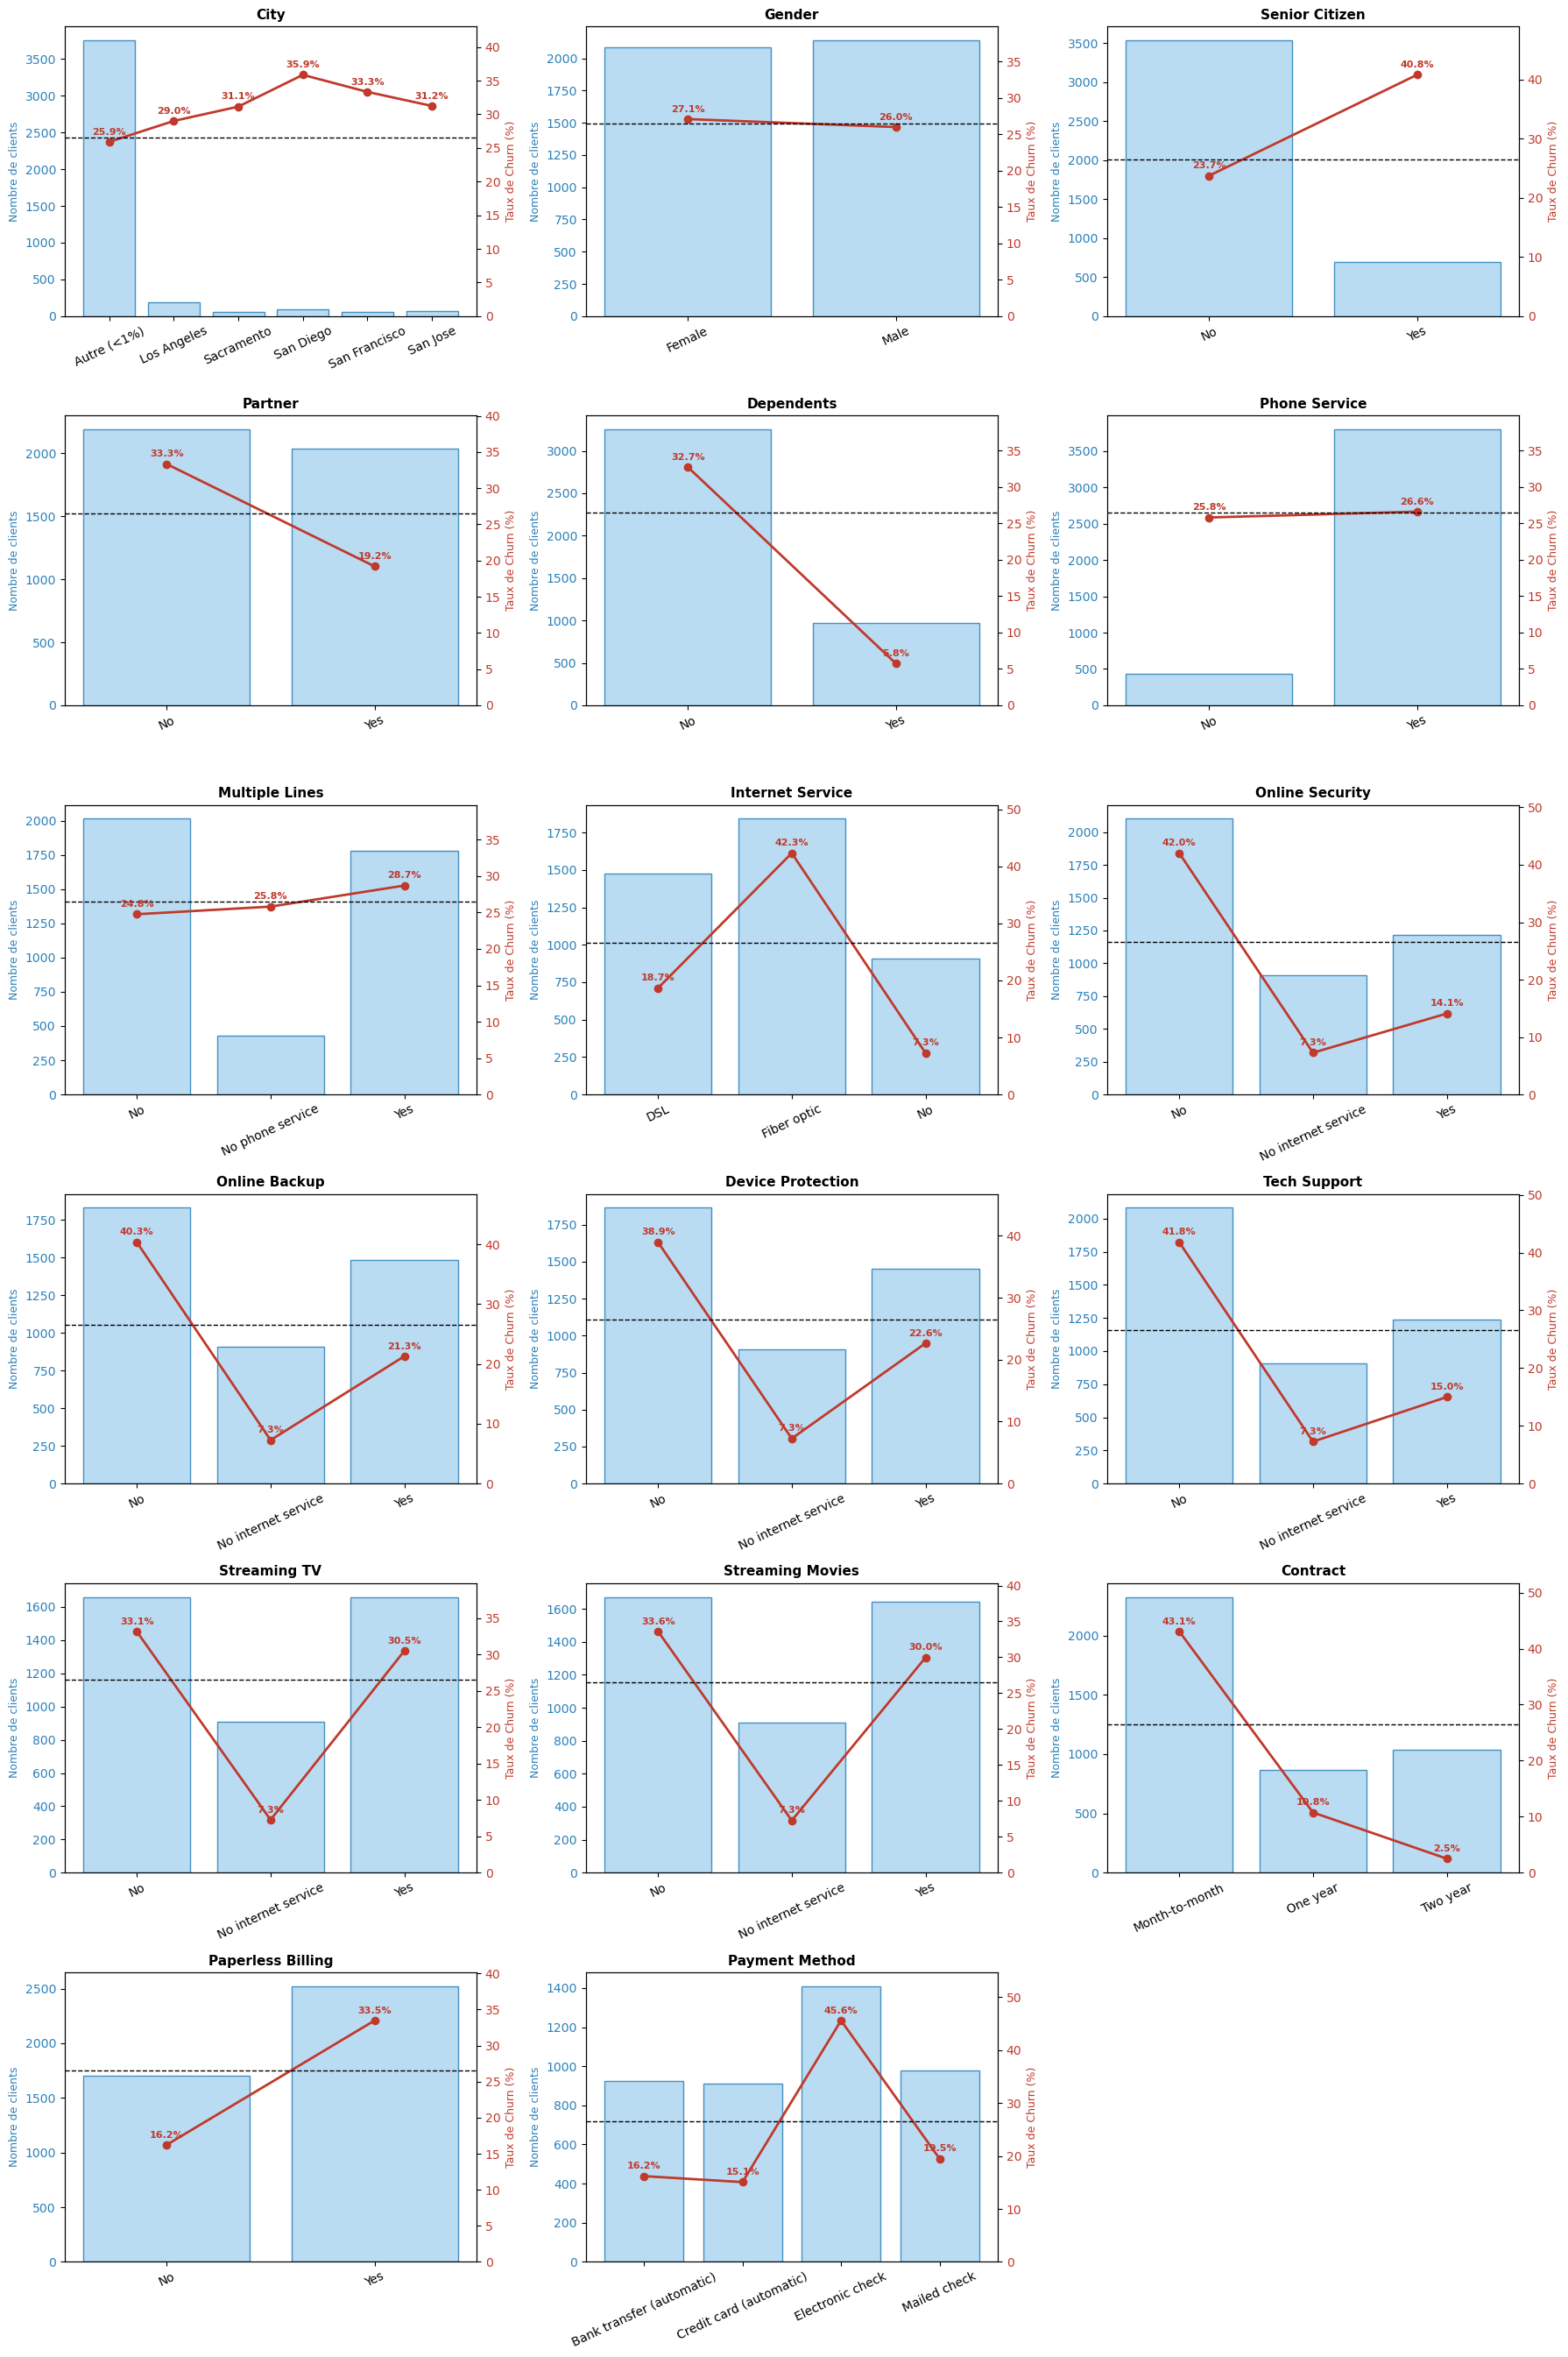

In [59]:
# 1. Préparer la cible numérique (0/1) et une copie propre de X_train
y_num = (y_train == "Yes").astype(int) if y_train.dtype == "object" else y_train
X_viz = X_train.copy()

# Regrouper City (< 1%) sous "Autre" pour que le graphique soit lisible
if "City" in X_viz.columns:
    freqs = X_viz["City"].value_counts(normalize=True)
    X_viz["City"] = X_viz["City"].where(X_viz["City"].map(freqs) >= 0.01, "Autre (<1%)")

# 2. Grille de sous-graphiques (3 graphiques par ligne)
n_vars = len(cat_cols)
n_cols_grid = 3
n_rows_grid = (n_vars + n_cols_grid - 1) // n_cols_grid

fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(18, 4.5 * n_rows_grid))
axes = np.array(axes).flatten()

churn_global = y_num.mean() * 100

for i, col in enumerate(cat_cols):
    ax1 = axes[i]
    
    # Calculer effectif et taux de churn par modalité
    stats = (
        pd.DataFrame({"mod": X_viz[col], "churn": y_num})
        .groupby("mod", observed=True)
        .agg(effectif=("churn", "count"), taux_churn=("churn", "mean"))
    )
    stats["taux_pct"] = stats["taux_churn"] * 100
    
    # --- Axe gauche : Histogramme / Barplot des effectifs ---
    bars = ax1.bar(stats.index.astype(str), stats["effectif"], color="#aed6f1", edgecolor="#2980b9", alpha=0.85, label="Effectif")
    ax1.set_ylabel("Nombre de clients", color="#2980b9", fontsize=9)
    ax1.tick_params(axis="y", labelcolor="#2980b9")
    ax1.tick_params(axis="x", rotation=25)
    ax1.set_title(col, fontweight="bold", fontsize=11)
    
    # --- Axe droit : Courbe du taux de churn (%) ---
    ax2 = ax1.twinx()
    ax2.plot(stats.index.astype(str), stats["taux_pct"], color="#c0392b", marker="o", linewidth=2, markersize=6, label="Taux Churn (%)")
    ax2.axhline(churn_global, color="black", linestyle="--", linewidth=1, label=f"Moyenne ({churn_global:.1f}%)")
    ax2.set_ylabel("Taux de Churn (%)", color="#c0392b", fontsize=9)
    ax2.tick_params(axis="y", labelcolor="#c0392b")
    ax2.set_ylim(0, max(stats["taux_pct"].max() * 1.2, churn_global * 1.5))
    
    # Afficher la valeur du taux de churn au-dessus de chaque point
    for idx, pct in enumerate(stats["taux_pct"]):
        ax2.annotate(f"{pct:.1f}%", (idx, pct), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8, fontweight="bold", color="#c0392b")

# Masquer les graphiques vides
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

apres calcul de p_value pour un seuil alpha=0.05 pour accepter ou rejeter l'hypothese de l'indepandance entre la cible et chque feature. Puis on calcule la valeur de V de cramer pour voir la force de signal et l'intensité de l'association avec un seuil de decision aussi de 0.05 

* **`Contract` :** C'est le prédicteur catégoriel le plus puissant ($V = 0.419$, $p = 4.17 \times 10^{-162}$), montrant une chute massive et ordonnée du taux de churn selon la durée d'engagement (**43,1 %** pour *Month-to-month*, **10,8 %** pour *One year*, et **2,5 %** pour *Two year*). **Donc :** conserver la variable et appliquer un `OrdinalEncoder` (`Month-to-month` = 0, `One year` = 1, `Two year` = 2) afin de respecter la hiérarchie temporelle du contrat.


* **`Online Security` :** Cette option présente un signal très fort ($V = 0.354$, $p = 1.62 \times 10^{-115}$), avec un churn atteignant **42,0 %** sans sécurité contre **14,1 %** avec, tandis que `"No internet service"` (**7,3 %**) répète l'information de la variable mère `Internet Service`. **Donc :** conserver la variable en fusionnant `"No internet service"` avec `"No"`, puis appliquer un encodage binaire (`0/1`) pour éliminer toute redondance.


* **`Tech Support` :** Son comportement est quasi symétrique à celui de `Online Security` ($V = 0.346$, $p = 1.36 \times 10^{-110}$), affichant **41,8 %** de churn sans support technique contre **15,0 %** lorsqu'il est activé. **Donc :** conserver la variable en fusionnant `"No internet service"` dans `"No"`, suivi d'un encodage binaire (`0/1`).


* **`Internet Service` :** Le type d'accès segmente fortement le risque ($V = 0.328$, $p = 1.24 \times 10^{-99}$), la Fibre optique concentrant un taux de résiliation élevé (**42,3 %**) face au DSL (**18,7 %**) et à l'absence d'Internet (**7,3 %**). **Donc :** conserver et appliquer un *Dummy Encoding* en fixant `"No"` comme état de référence `(0, 0)` pour obtenir deux indicatrices propres (`is_DSL` et `is_Fiber_optic`).


* **`Payment Method` :** Cette variable offre un signal fort ($V = 0.308$, $p = 2.23 \times 10^{-86}$) porté par le paiement par chèque électronique (*Electronic check*) qui culmine à **45,6 %** de churn, contre **15,1 % à 19,5 %** pour les trois autres modes. **Donc :** conserver et encoder via `OneHotEncoder(drop='first')` car ses 4 modalités sont nominales et équilibrées.


* **`Online Backup` :** L'absence de sauvegarde en ligne s'accompagne d'un sur-risque net ($V = 0.297$, $p = 1.00 \times 10^{-81}$), avec **40,3 %** de churn contre **21,3 %** avec l'option. **Donc :** conserver en fusionnant `"No internet service"` avec `"No"`, puis encoder en binaire (`0/1`).


* **`Device Protection` :** L'option affiche un lien modéré à fort ($V = 0.280$, $p = 1.01 \times 10^{-72}$), séparant les abonnés sans protection (**38,9 %** de churn) de ceux qui en disposent (**22,6 %**). **Donc :** conserver en fusionnant `"No internet service"` avec `"No"`, puis encoder en binaire (`0/1`).


* **`Dependents` :** C'est un facteur de rétention très marqué ($V = 0.257$, $p = 1.54 \times 10^{-62}$), où les clients ayant des personnes à charge ne résilient qu'à **5,8 %** contre **32,7 %** pour ceux sans personnes à charge. **Donc :** conserver et appliquer un encodage binaire simple (`0/1`).


* **`Streaming Movies` :** Son score global ($V = 0.231$, $p = 9.18 \times 10^{-50}$) est surtout tiré par le creux de `"No internet service"` (**7,3 %**), alors que l'écart entre abonnés Internet est faible (**30,0 %** avec films vs **33,6 %** sans). **Donc :** fusionner `"No internet service"` avec `"No"`, encoder en binaire (`0/1`), et vérifier son utilité marginale lors de la sélection de variables.


* **`Streaming TV` :** Elle présente exactement le même profil que `Streaming Movies` ($V = 0.230$, $p = 3.46 \times 10^{-49}$), avec un écart faible parmi les abonnés Internet (**30,5 %** avec TV vs **33,1 %** sans). **Donc :** fusionner `"No internet service"` avec `"No"`, encoder en binaire (`0/1`), et tester son apport en sélection de variables.


* **`Paperless Billing` :** La facturation dématérialisée double le taux de résiliation ($V = 0.191$, $p = 2.00 \times 10^{-35}$), passant de **16,2 %** (papier) à **33,5 %** (électronique). **Donc :** conserver et encoder en binaire (`0/1`).


* **`Partner` :** Les clients en couple présentent une meilleure rétention ($V = 0.160$, $p = 3.39 \times 10^{-25}$) avec **19,2 %** de churn contre **33,3 %** chez les célibataires. **Donc :** conserver et encoder en binaire (`0/1`).


* **`Senior Citizen` :** Bien que minoritaires dans l'échantillon (~16 %), les seniors affichent un sur-risque très net ($V = 0.142$, $p = 2.29 \times 10^{-20}$) à **40,8 %** de churn contre **23,7 %** pour le reste de la clientèle. **Donc :** conserver et encoder en binaire (`0/1`).


* **`Multiple Lines` :** Le signal statistique est très faible ($V = 0.043$, $p = 0.0216$), mais les modalités suivent une progression physique logique allant de 0 ligne (**25,8 %**), à 1 ligne (**24,8 %**), puis aux lignes multiples (**28,7 %**). **Donc :** conserver et appliquer un `OrdinalEncoder` (`No phone service` = 0, `No` = 1, `Yes` = 2).


* **`Phone Service` :** Marginalement non significative ($V = 0.005$, $p = 0.765$), sa modalité minoritaire `"No"` (9,6 % du dataset, soit un effectif suffisant) conserve exactement le même taux de churn que la moyenne globale (**25,8 %** vs **26,6 %**). **Donc :** conserver avec un encodage binaire simple (`0/1`), notamment pour permettre d'éventuelles interactions dans les modèles d'arbres.


* **`Gender` :** Totalement indépendante de la cible ($V = 0.012$, $p = 0.442$), avec des effectifs équilibrés (~50/50) et des taux de churn quasi identiques chez les femmes (**27,1 %**) et les hommes (**26,0 %**). **Donc :** appliquer un encodage binaire (`0/1`) en base, mais la placer comme candidate prioritaire à la suppression lors de la sélection de variables.


* **`City` :** À l'état brut, le test n'est pas significatif ($p = 0.240$) et son $V$ de Cramer (`0.519`) est un artefact dû aux 1 129 micro-villes (dont 971 sous 0,1 % qui créeraient une catégorie `"Autre"` ultra-dominante à 57,6 %). **Donc :** supprimer (`drop`) cette variable, car l'information spatiale est déjà quantifiée de façon continue et sans explosion dimensionnelle par `Latitude` et `Longitude`.

# Les features entre elles

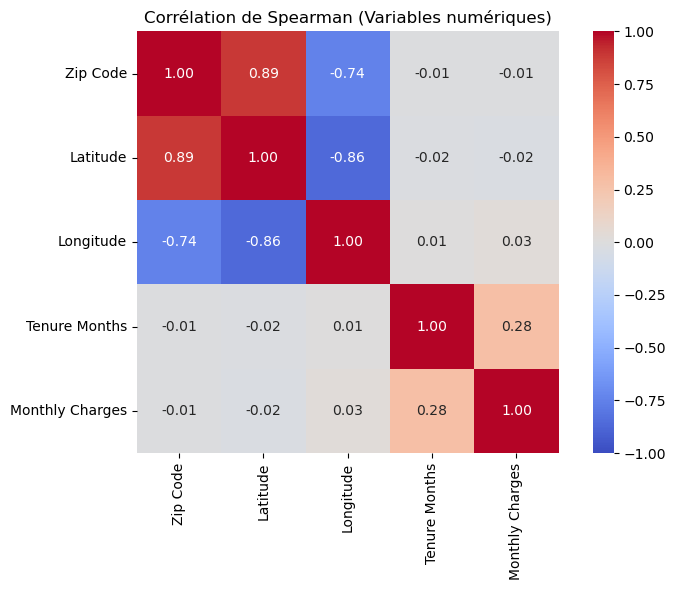

=== Paires numériques fortement corrélées (|rho| > 0.85) ===
Latitude   Zip Code    0.889528
Longitude  Latitude    0.862460
dtype: float64 

=== VIF par variable numérique ===
Latitude           8.409880
Zip Code           5.067332
Longitude          4.291375
Monthly Charges    1.073114
Tenure Months      1.072688
Name: VIF, dtype: float64


In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# --- 1. Matrice de corrélation de Spearman ---
corr = X_train[num_cols].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Corrélation de Spearman (Variables numériques)")
plt.tight_layout()
plt.show()

# Paires fortement corrélées (|rho| > 0.85)
strong = corr.abs().where(~mask).stack().loc[lambda s: s > 0.85]
print("=== Paires numériques fortement corrélées (|rho| > 0.85) ===")
print(strong.sort_values(ascending=False), "\n")

# --- 2. Calcul du VIF (Variance Inflation Factor) ---
Xv = sm.add_constant(X_train[num_cols].dropna())
vif = pd.Series(
    [variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
    index=num_cols,
    name="VIF"
)
print("=== VIF par variable numérique ===")
print(vif.sort_values(ascending=False))

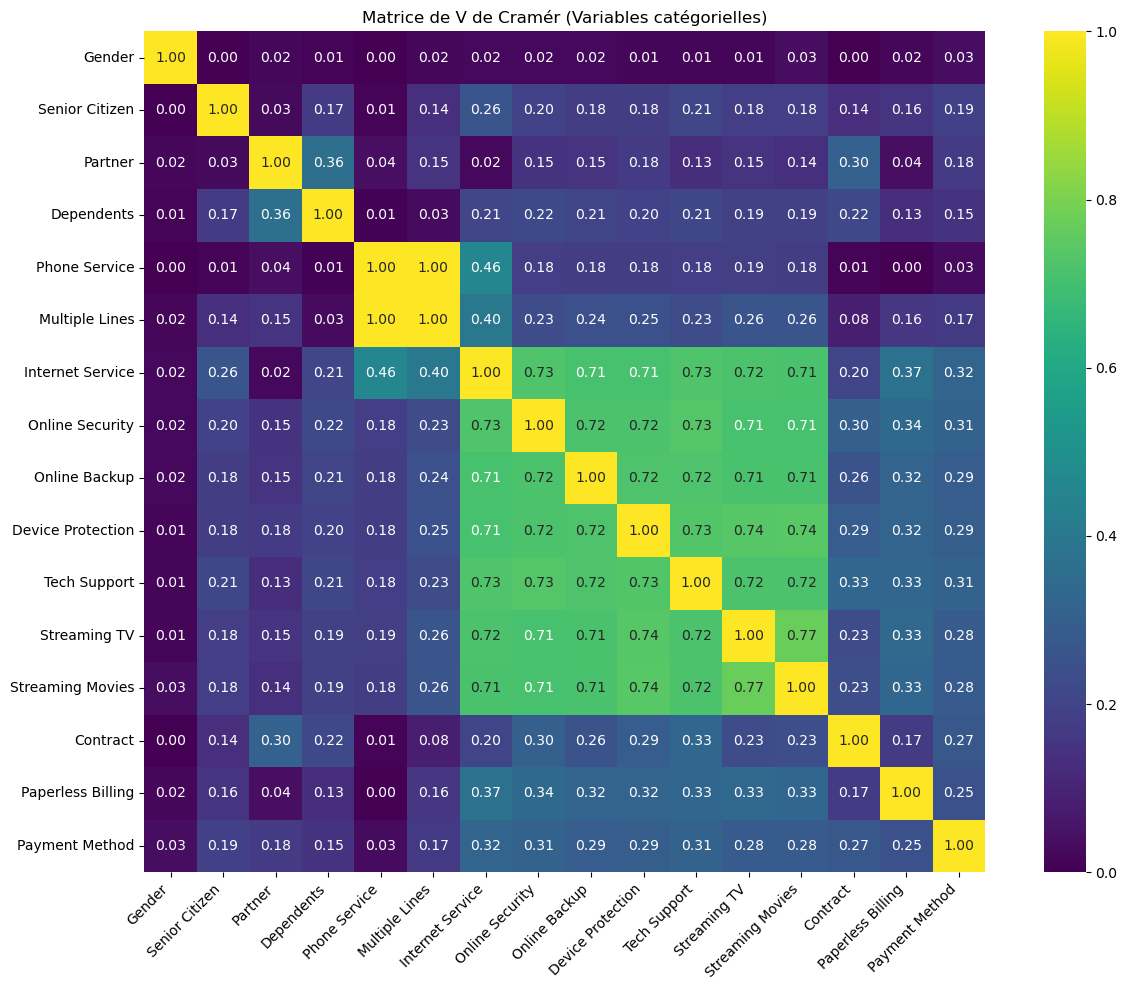

=== Paires catégorielles fortement associées (V > 0.70) ===
Multiple Lines     Phone Service        1.000000
Streaming Movies   Streaming TV         0.772837
                   Device Protection    0.740389
Streaming TV       Device Protection    0.736053
Tech Support       Online Security      0.732773
                   Device Protection    0.726995
Online Security    Internet Service     0.726155
Tech Support       Internet Service     0.725556
                   Online Backup        0.721045
Device Protection  Online Backup        0.719122
Online Backup      Online Security      0.718547
Streaming Movies   Tech Support         0.716559
Streaming TV       Tech Support         0.716193
Device Protection  Online Security      0.715872
Streaming TV       Internet Service     0.715411
                   Online Backup        0.714167
Streaming Movies   Internet Service     0.713959
                   Online Backup        0.713431
                   Online Security      0.708176
Streaming

In [63]:
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    n = ct.values.sum()
    r, k = ct.shape
    denom = n * (min(r, k) - 1)
    if denom == 0:
        return 0.0
    chi2 = chi2_contingency(ct)[0]
    return np.sqrt(chi2 / denom)

# Exclure City si encore présent dans cat_cols (trop de modalités)
cat_cols_clean = [c for c in cat_cols if X_train[c].nunique() <= 15]

V = pd.DataFrame(
    [[cramers_v(X_train[a], X_train[b]) for b in cat_cols_clean] for a in cat_cols_clean],
    index=cat_cols_clean,
    columns=cat_cols_clean
)


plt.figure(figsize=(13, 10))
sns.heatmap(
    V,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    vmin=0,
    vmax=1,
    square=True
)
plt.title("Matrice de V de Cramér (Variables catégorielles)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Paires catégorielles fortement associées (V > 0.70)
mask_strict = np.triu(np.ones_like(V, dtype=bool))
strong_cat = V.where(~mask_strict).stack().loc[lambda s: s > 0.70]
print("=== Paires catégorielles fortement associées (V > 0.70) ===")
print(strong_cat.sort_values(ascending=False))

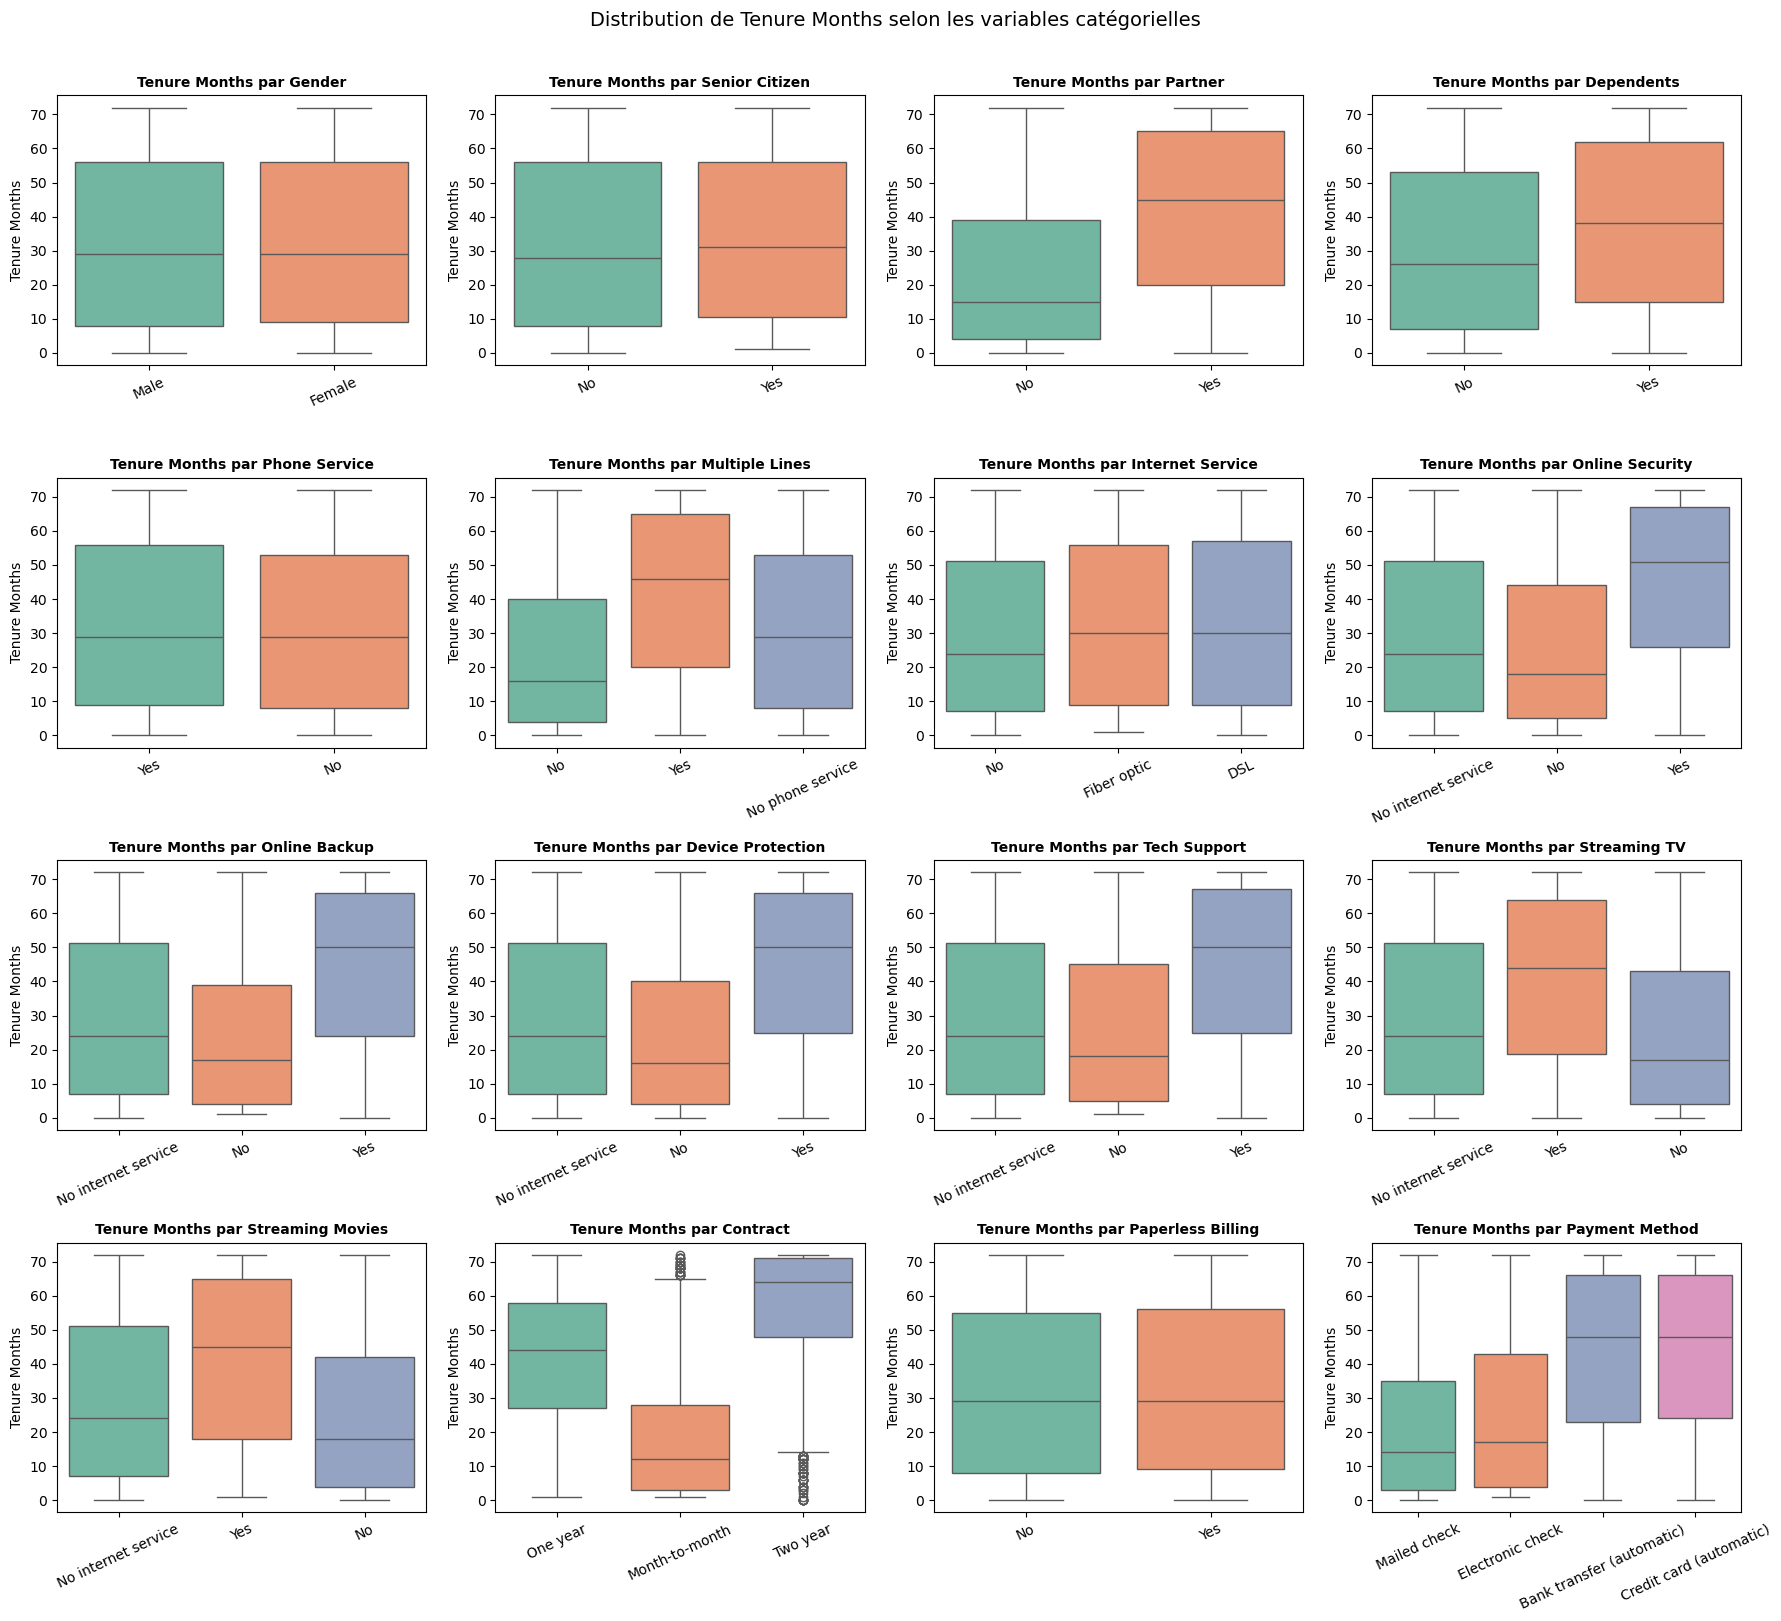

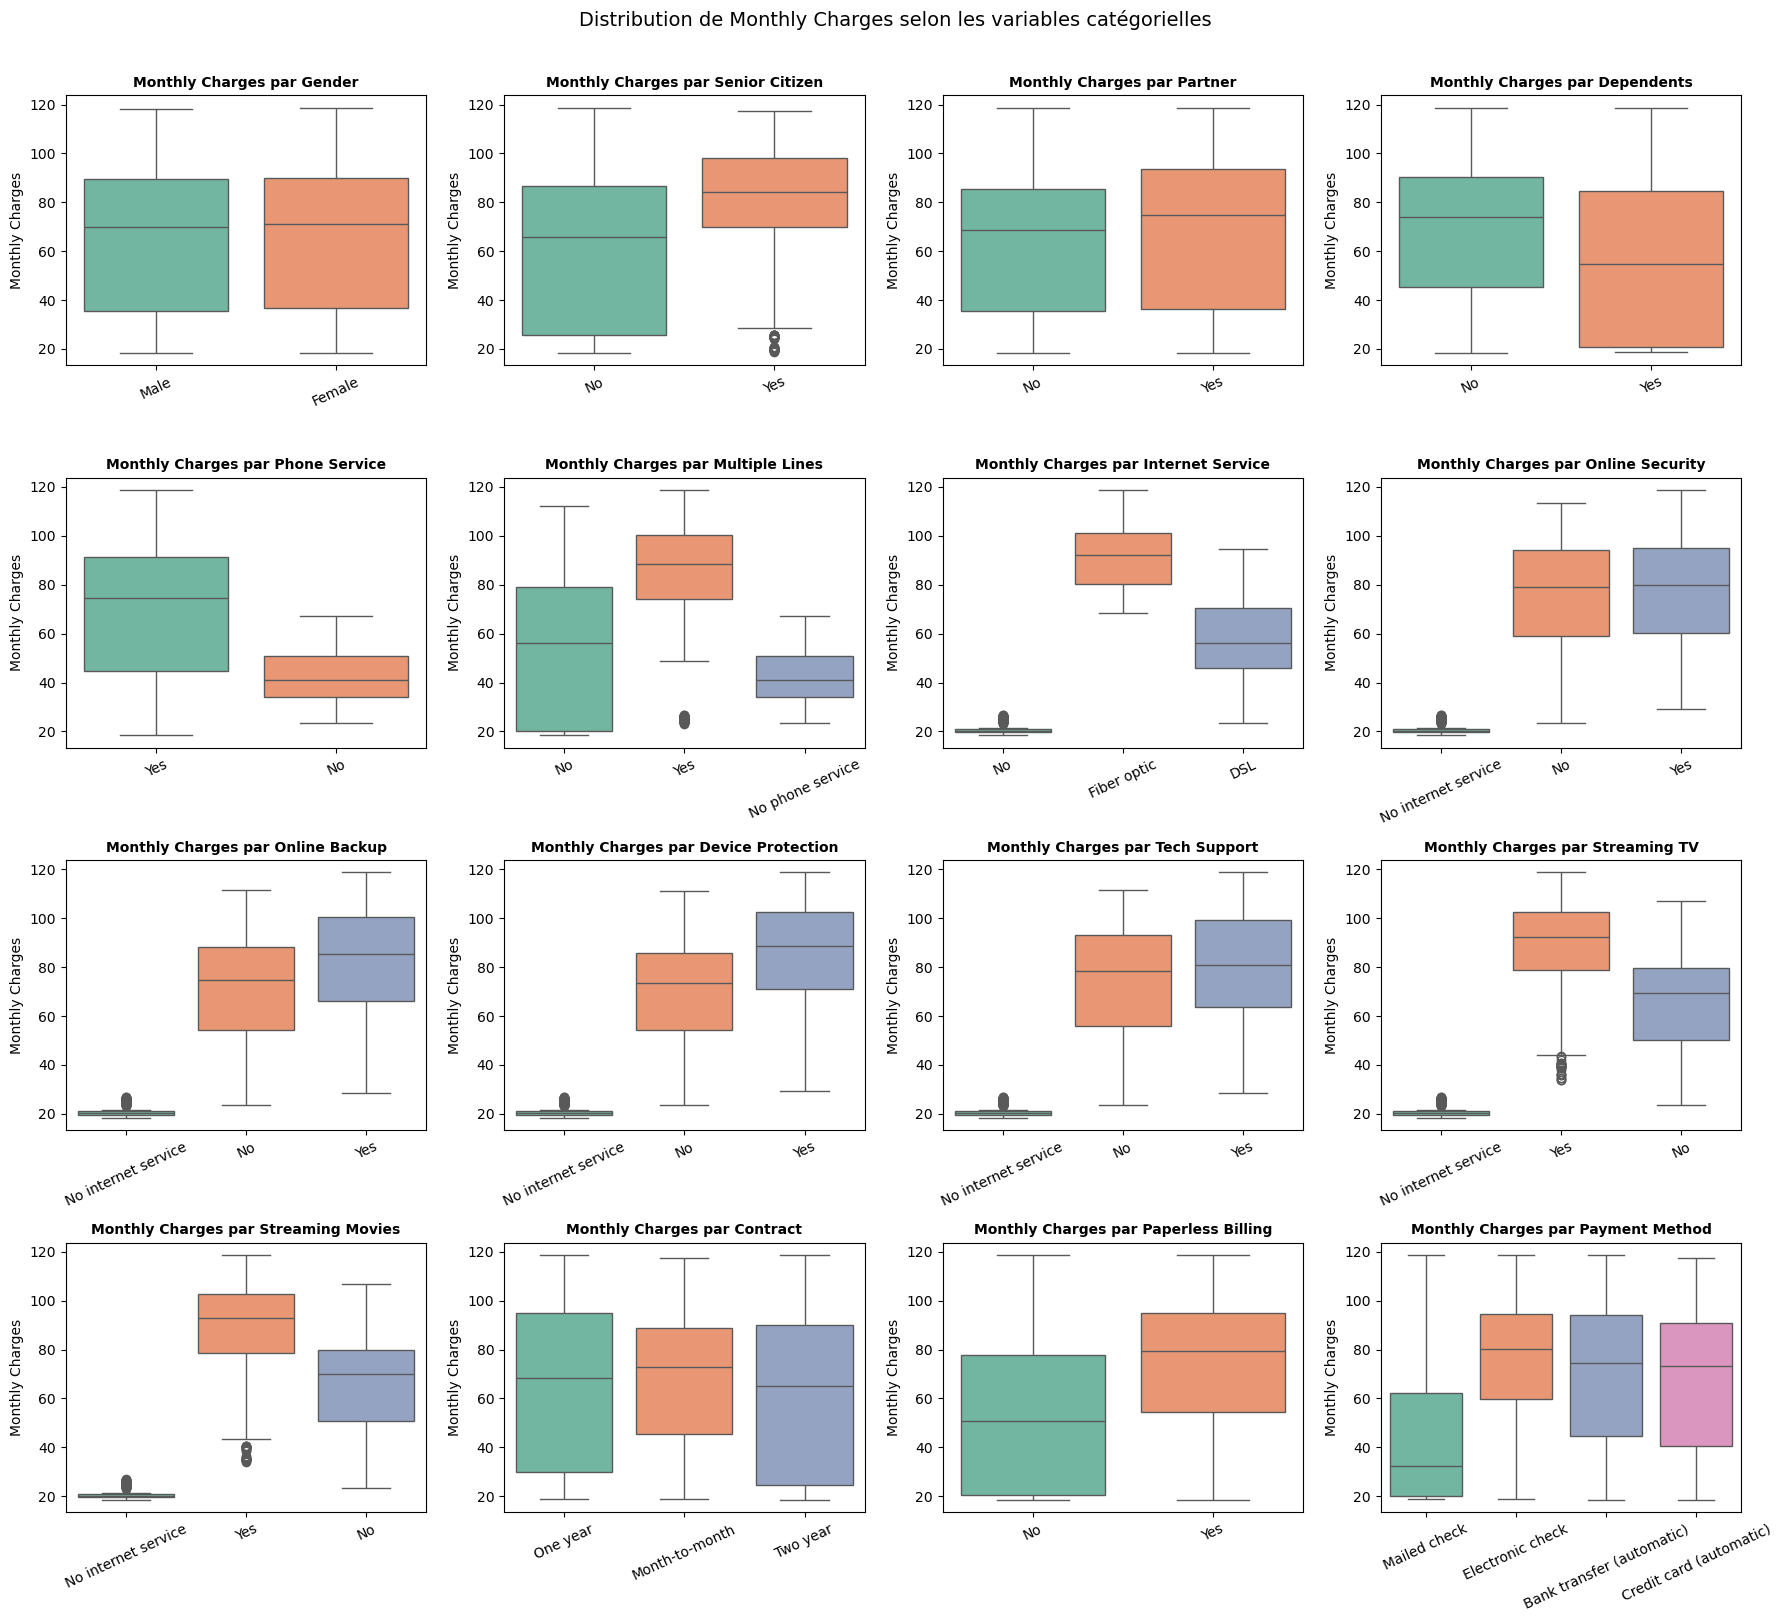

In [66]:
num_box = [c for c in ["Tenure Months", "Monthly Charges", "Total Charges"] if c in X_train.columns]
cat_box = [c for c in cat_cols if X_train[c].nunique() <= 6]

for num_c in num_box:
    n_vars = len(cat_box)
    n_cols_grid = 4
    n_rows_grid = (n_vars + n_cols_grid - 1) // n_cols_grid

    fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(18, 4 * n_rows_grid))
    axes = np.array(axes).flatten()

    for i, cat_c in enumerate(cat_box):
        sns.boxplot(
            data=X_train,
            x=cat_c,
            y=num_c,
            hue=cat_c,      # Ajouté pour supprimer le FutureWarning
            palette="Set2",
            legend=False,   # Évite d'afficher une légende redondante
            ax=axes[i]
        )
        axes[i].set_title(f"{num_c} par {cat_c}", fontsize=10, fontweight="bold")
        axes[i].set_xlabel("")
        axes[i].tick_params(axis="x", rotation=25)

    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(f"Distribution de {num_c} selon les variables catégorielles", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()